# Deep Learning PR 2: Adult Income Classification

## Objective

I use a multilayer perceptron (MLP) to predict whether annual income is `<=50K` or `>50K` from demographic and work-related features.

**Dataset:** Adult Income (`adult.csv`)  
**Target:** `income` (`0 = <=50K`, `1 = >50K`)  
**Main metric:** F1-score for the `>50K` class, alongside Precision, Recall, Accuracy and ROC-AUC.

The notebook follows the seven tasks in the project brief. Model choices are compared on a validation set; the test set is kept for final reporting.

In [1]:
# Data handling and plots
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:
# Neural network tools
import tensorflow as tf
from tensorflow import keras

c:\Users\HP\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.1). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


In [3]:
# Data splitting, scaling and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

In [4]:
# Reproducibility and output folder
np.random.seed(42)
tf.random.set_seed(42)
os.makedirs("plots", exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Plots will be saved in:", os.path.abspath("plots"))

TensorFlow version: 2.21.0
Plots will be saved in: c:\Users\HP\Downloads\DL_PR2_Student_Cell_By_Cell\DL_PR2_Student_Cell_By_Cell\plots


In [5]:
# Store class-1 F1 after each epoch for the BCE vs MSE comparison
class ValidationF1Callback(keras.callbacks.Callback):
    def __init__(self, X_val, y_val):
        super().__init__()
        self.X_val = X_val
        self.y_val = np.asarray(y_val).reshape(-1)
        self.values = []

    def on_epoch_end(self, epoch, logs=None):
        prob = self.model.predict(self.X_val, verbose=0).ravel()
        pred = (prob > 0.5).astype(int)
        score = f1_score(self.y_val, pred, zero_division=0)
        self.values.append(float(score))

### Observation

The version line confirms which TensorFlow runtime is being used. The plots directory is created before any figure is saved, so later `savefig()` calls have a valid destination.


# Task 1 - Data Loading, Cleaning & Exploratory Data Analysis

### Objective
First I will load the Adult Income dataset, clean the missing values and understand the data before training the neural network.

### Expected output
Clean data, four EDA plots and a prepared train/test dataset.

In [6]:
# Load the CSV file

df = pd.read_csv("adult.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (48842, 15)

Columns:
['age', 'workclass', 'fnlwgt', 'education', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

First 5 rows:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


### Observation

Check the printed shape and columns. For the supplied combined CSV, the initial dataset should be about 48,842 rows by 15 columns; use the actual printed shape if your file differs.


In [7]:
# Remove extra spaces from text columns

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Text columns cleaned.")

Text columns cleaned.


### Observation

Text values are now stripped of leading and trailing spaces. This prevents the same category from being accidentally treated as two different labels.


In [8]:
# Replace ? with missing values

df.replace("?", np.nan, inplace=True)

print("Missing values:")
print(df.isnull().sum())

Missing values:
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


### Observation

The missing-value table shows which columns contain `NaN` after replacing `?`. Record the counts produced by this CSV rather than assuming the assignment's approximate counts.


In [9]:
# Remove rows that contain missing values

rows_before_missing = len(df)
print("Rows before:", rows_before_missing)

df.dropna(inplace=True)

print("Rows after :", len(df))
print("Rows removed:", rows_before_missing - len(df))

Rows before: 48842
Rows after : 45222
Rows removed: 3620


### Observation

The printed before/after counts show the number of records retained by complete-case cleaning. If your count differs from the assignment estimate, report the actual dataset-specific result.


In [10]:
# Drop columns that are not needed

df.drop(["fnlwgt", "education"], axis=1, inplace=True)

print("New shape:", df.shape)
print(df.columns.tolist())

New shape: (45222, 13)
['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


### Observation

Two columns are removed, while `educational-num` and `income` remain. The printed column list confirms the preprocessing step.


In [11]:
# Convert target column into 0 and 1

df["income"] = (df["income"] == ">50K").astype(int)

print(df["income"].value_counts())

print("\nPercentage:")
print((df["income"].value_counts(normalize=True) * 100).round(2))

income
0    34014
1    11208
Name: count, dtype: int64

Percentage:
income
0    75.22
1    24.78
Name: proportion, dtype: float64


### Observation

The target count/percentage output should show class 0 (`<=50K`) is larger than class 1 (`>50K`). Use those percentages when describing class imbalance.


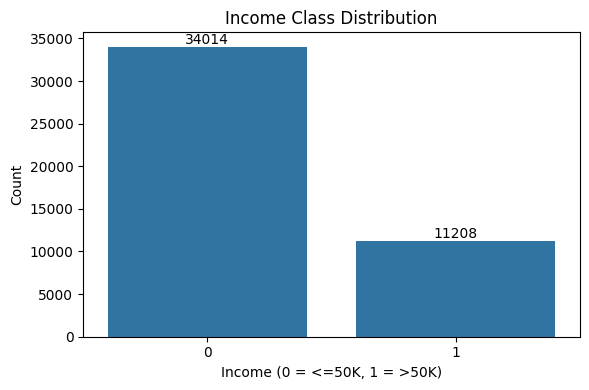

In [12]:
# Plot the class distribution

plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x="income")

plt.title("Income Class Distribution")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Count")

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("plots/eda_class_balance.png", dpi=150)
plt.show()

### Observation

Compare the two annotated bars. The taller class-0 bar indicates imbalance; this is why class-1 Precision, Recall and F1 are reported along with accuracy.


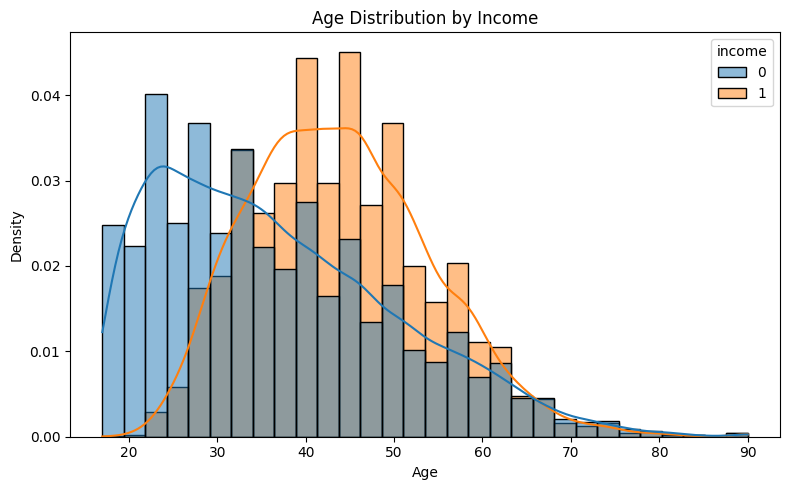

In [13]:
# Age distribution by income

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="income",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title("Age Distribution by Income")
plt.xlabel("Age")
plt.ylabel("Density")

plt.tight_layout()
plt.savefig("plots/eda_age.png", dpi=150)
plt.show()

### Observation

Look at the overlap between the two age distributions. Overlap means age alone cannot perfectly distinguish the two income classes.


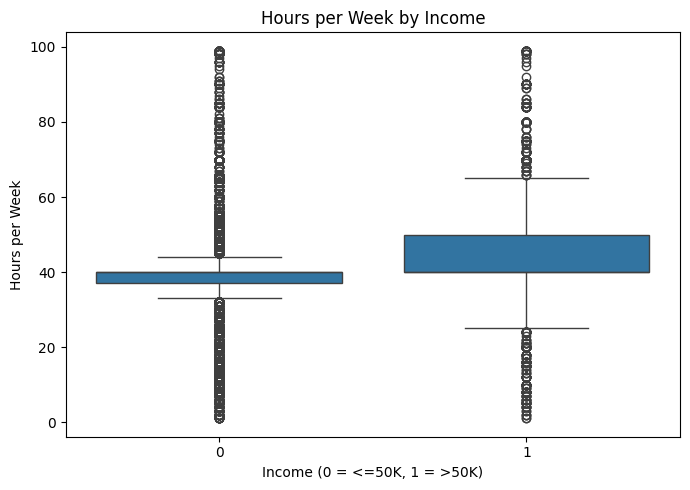

In [14]:
# Working hours by income

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="income",
    y="hours-per-week"
)

plt.title("Hours per Week by Income")
plt.xlabel("Income (0 = <=50K, 1 = >50K)")
plt.ylabel("Hours per Week")

plt.tight_layout()
plt.savefig("plots/eda_hours.png", dpi=150)
plt.show()

### Observation

Compare the median lines and interquartile ranges. Any difference suggests working hours may contain signal, while overlap indicates it is not a perfect separator by itself.


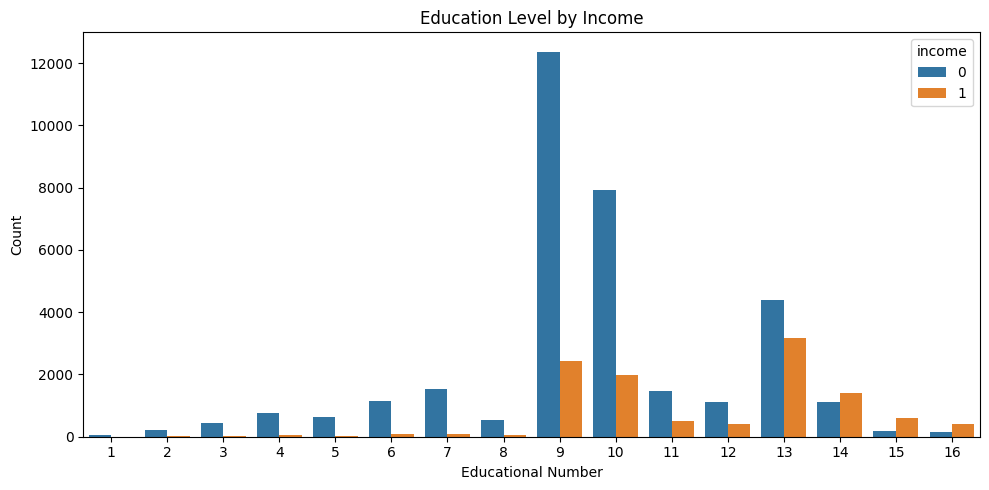

In [15]:
# Education level by income

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="educational-num",
    hue="income"
)

plt.title("Education Level by Income")
plt.xlabel("Educational Number")
plt.ylabel("Count")

plt.tight_layout()
plt.savefig("plots/eda_education.png", dpi=150)
plt.show()

### Observation

The countplot compares the number of records per education level and income class. Because it shows counts rather than within-level percentages, the largest bars also reflect how common each education level is in the dataset.


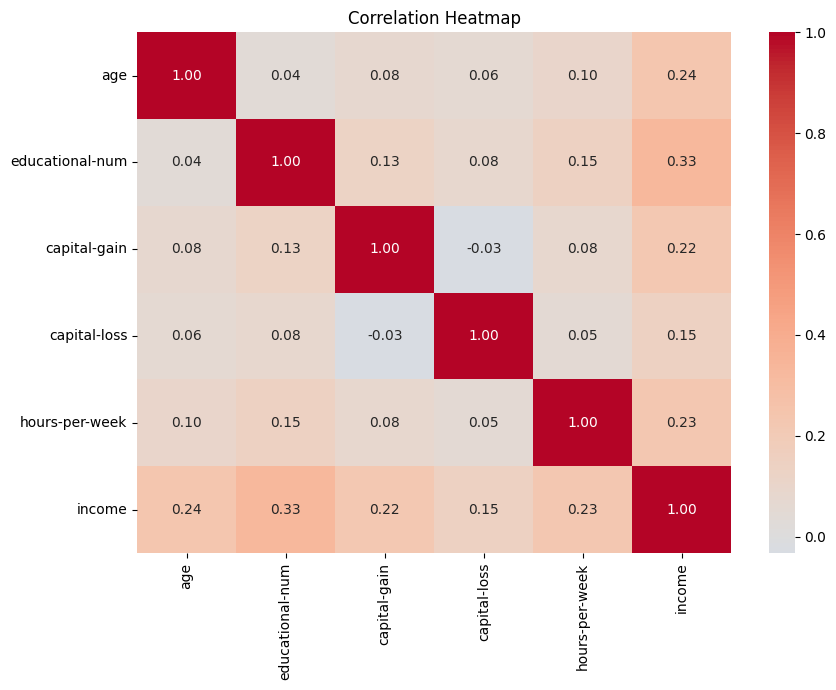

In [16]:
# Correlation heatmap

plt.figure(figsize=(9, 7))

numeric_data = df.select_dtypes(include="number")

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("plots/eda_correlation.png", dpi=150)
plt.show()

### Observation

The heatmap displays numeric correlations, including the encoded income target. Correlation shows linear association, not causation, and a weak correlation does not rule out a nonlinear relationship.


In [17]:
# Separate input and target

X = df.drop("income", axis=1)
y = df["income"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45222, 12)
y shape: (45222,)


### Observation

`X` contains predictors and `y` contains the binary target. Confirm the row counts match and the target is not present among the predictors.


In [18]:
# One-hot encode categorical columns

X = pd.get_dummies(
    X,
    drop_first=True
)

print("Shape after one-hot encoding:", X.shape)

Shape after one-hot encoding: (45222, 80)


### Observation

One-hot encoding expands categorical columns into indicator columns. The resulting feature count is printed; it depends on the categories actually present after cleaning.


In [19]:
# Train-test split, then reserve validation data from the training pool

X_train_pool, X_test, y_train_pool, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# A fixed validation set makes model comparisons fair and keeps the test set
# untouched until final evaluation.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=0.10,
    random_state=42,
    stratify=y_train_pool
)

print("Initial development pool (80%):", X_train_pool.shape)
print("Training set (72% of all data):", X_train.shape)
print("Validation set (8% of all data):", X_val.shape)
print("Test set (20% of all data):", X_test.shape)

for split_name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"\n{split_name} class ratio:")
    print((labels.value_counts(normalize=True).sort_index() * 100).round(2))

Initial development pool (80%): (36177, 80)
Training set (72% of all data): (32559, 80)
Validation set (8% of all data): (3618, 80)
Test set (20% of all data): (9045, 80)

Train class ratio:
income
0    75.22
1    24.78
Name: proportion, dtype: float64

Validation class ratio:
income
0    75.21
1    24.79
Name: proportion, dtype: float64

Test class ratio:
income
0    75.21
1    24.79
Name: proportion, dtype: float64


### Observation

The training, validation and test ratios should remain close because all three splits are stratified. The test set is held aside for final reporting only.


In [20]:
# Scale numeric columns only; fit the scaler on the training set

numeric_cols = [
    "age",
    "educational-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train.loc[:, numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_val.loc[:, numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test.loc[:, numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train = X_train.astype("float32")
X_val = X_val.astype("float32")
X_test = X_test.astype("float32")

print("Numeric columns scaled using training-set statistics only.")
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
display(X_train.head())

Numeric columns scaled using training-set statistics only.
X_train: (32559, 80) | X_val: (3618, 80) | X_test: (9045, 80)


C:\Users\HP\AppData\Local\Temp\ipykernel_22868\3174875291.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.24299878  1.3185601   0.33626287 ...  1.16743745 -0.64603437
 -1.40164762]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
C:\Users\HP\AppData\Local\Temp\ipykernel_22868\3174875291.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 1.1242129  -2.38475825 -0.04544415 ...  0.73432721 -1.2151012
 -0.04544415]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
C:\Users\HP\AppData\Local\Temp\ipykernel_22868\3174875291.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise 

,age,educational-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
22682,1.242999,1.124213,-0.147847,-0.217543,2.658099,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
16084,1.318560,-2.384758,-0.147847,-0.217543,-0.083197,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5844,0.336263,-0.045444,-0.147847,-0.217543,0.332151,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
24736,-0.192666,-0.045444,-0.147847,-0.217543,-0.083197,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
48819,-0.041544,1.124213,1.843922,-0.217543,0.332151,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


### Observation

The scaler is fitted on training rows only and then applied to validation and test rows. Numeric features are standardized, while one-hot columns remain 0/1 indicators.


# Task 2 - MLP Architecture - Baseline ANN

### Objective
I will start with a simple two-hidden-layer neural network and use it as the baseline for later experiments.

In [21]:
# Keep optimizer settings in one place

def get_optimizer(name):
    if not isinstance(name, str):
        return name

    name = name.strip().lower()
    if name == "adam":
        return keras.optimizers.Adam()
    if name == "adam explicit":
        return keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999)
    if name == "rmsprop":
        return keras.optimizers.RMSprop()
    if name == "sgd":
        return keras.optimizers.SGD()
    if name == "sgd + momentum":
        return keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
    raise ValueError(f"Unsupported optimizer: {name}")

In [22]:
# Build the same two-hidden-layer ANN for each controlled experiment

def build_ann(
    input_dim,
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
):
    activation = str(activation).strip().lower()
    initializer = str(initializer).strip().lower().replace(" ", "_")
    model = keras.Sequential([keras.Input(shape=(input_dim,))])

    for units in hidden_units:
        model.add(keras.layers.Dense(
            units,
            activation=None if use_batch_norm else activation,
            kernel_initializer=initializer
        ))
        if use_batch_norm:
            model.add(keras.layers.BatchNormalization())
            model.add(keras.layers.Activation(activation))

    model.add(keras.layers.Dense(
        1, activation="sigmoid", kernel_initializer=initializer
    ))
    model.compile(
        optimizer=get_optimizer(optimizer),
        loss=loss,
        metrics=["accuracy"]
    )
    return model

In [23]:
# Baseline: Dense(128) -> Dense(64) -> Dense(1)
model_base = build_ann(input_dim=X_train.shape[1])
model_base.summary()

input_dim = X_train.shape[1]
manual_params = (input_dim * 128 + 128) + (128 * 64 + 64) + (64 * 1 + 1)
print("Input features:", input_dim)
print("Manual parameter count:", manual_params)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Input features: 80
Manual parameter count: 18689


In [24]:
# Baseline: Dense(128) -> Dense(64) -> Dense(1)
model_base = build_ann(input_dim=X_train.shape[1])
model_base.summary()

input_dim = X_train.shape[1]
manual_params = (input_dim * 128 + 128) + (128 * 64 + 64) + (64 * 1 + 1)
print("Input features:", input_dim)
print("Manual parameter count:", manual_params)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,689 (73.00 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

Input features: 80
Manual parameter count: 18689


### Architecture note

For a binary target, one sigmoid output gives the probability of `>50K`; a two-neuron softmax is not needed. A fully connected MLP fits this structured, one-hot-encoded tabular data.

### Observation

The model summary gives the trainable parameter count. Compare it with the manually calculated count printed below; a mismatch would indicate an architecture or input-dimension issue. The sigmoid output is a probability for class `>50K`.


In [25]:
# Train the baseline model

base_f1_callback = ValidationF1Callback(X_val, y_val)
history_base = model_base.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[base_f1_callback],
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8424 - loss: 0.3364 - val_accuracy: 0.8543 - val_loss: 0.3160
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8521 - loss: 0.3143 - val_accuracy: 0.8541 - val_loss: 0.3139
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8549 - loss: 0.3105 - val_accuracy: 0.8535 - val_loss: 0.3131
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8565 - loss: 0.3073 - val_accuracy: 0.8532 - val_loss: 0.3133
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8584 - loss: 0.3042 - val_accuracy: 0.8546 - val_loss: 0.3136
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8596 - loss: 0.3012 - val_accuracy: 0.8546 - val_loss: 0.3146
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8615 - loss: 0.2984 - val_accuracy: 0.8552 - val_loss: 0.3153
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8628 - loss: 0.2957 - val_accuracy: 0.

### Observation

The fit log provides training and validation loss/accuracy for each epoch. Compare both curves rather than relying on training accuracy alone; a widening gap may indicate overfitting.


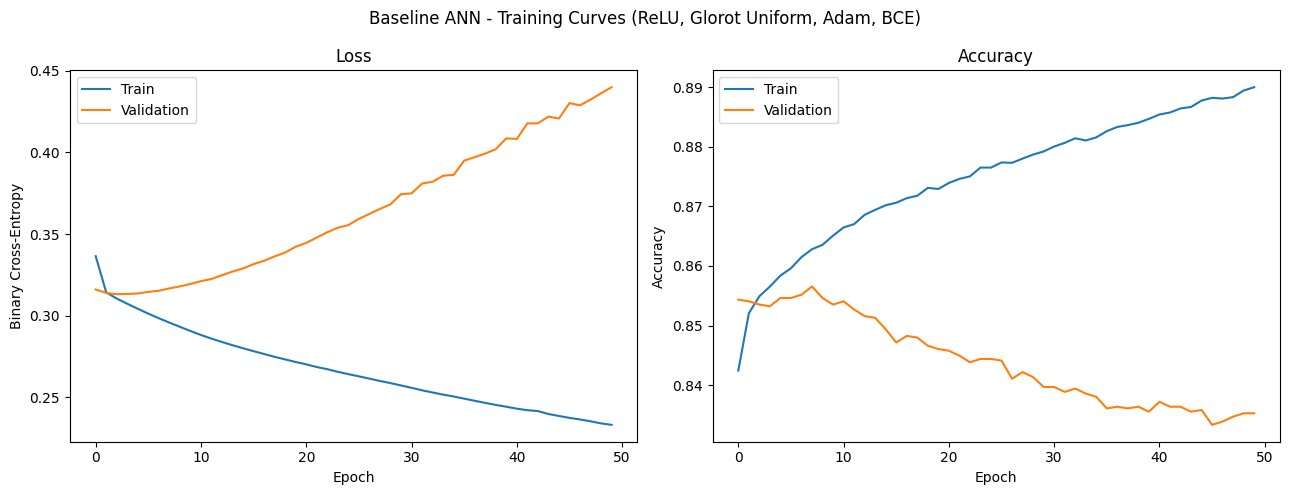

In [26]:
# Baseline training curves: loss and accuracy side by side

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history_base.history["loss"], label="Train")
axes[0].plot(history_base.history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()

axes[1].plot(history_base.history["accuracy"], label="Train")
axes[1].plot(history_base.history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.suptitle("Baseline ANN - Training Curves (ReLU, Glorot Uniform, Adam, BCE)")
plt.tight_layout()
plt.savefig("plots/baseline_training_curves.png", dpi=150)
plt.show()

### Observation

The loss and accuracy curves show the learning trend. Prefer a validation curve that improves or stabilizes without an increasingly large gap from training.


In [27]:
# Evaluate baseline

y_prob_base_val = model_base.predict(X_val, verbose=0).ravel()
y_pred_base_val = (y_prob_base_val > 0.5).astype(int)
base_val_precision = precision_score(y_val, y_pred_base_val, zero_division=0)
base_val_recall = recall_score(y_val, y_pred_base_val, zero_division=0)
base_val_f1 = f1_score(y_val, y_pred_base_val, zero_division=0)
print("Validation Precision:", round(base_val_precision, 4))
print("Validation Recall   :", round(base_val_recall, 4))
print("Validation F1       :", round(base_val_f1, 4))

Validation Precision: 0.7204
Validation Recall   : 0.5485
Validation F1       : 0.6228


In [28]:
y_prob_base = model_base.predict(
    X_test,
    verbose=0
).ravel()

y_pred_base = (y_prob_base > 0.5).astype(int)

base_accuracy = accuracy_score(y_test, y_pred_base)
base_precision = precision_score(y_test, y_pred_base, zero_division=0)
base_recall = recall_score(y_test, y_pred_base, zero_division=0)
base_f1 = f1_score(y_test, y_pred_base, zero_division=0)
base_auc = roc_auc_score(y_test, y_prob_base)

print("Accuracy :", base_accuracy)
print("Precision:", base_precision)
print("Recall   :", base_recall)
print("F1 Score :", base_f1)
print("ROC-AUC  :", base_auc)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_base,
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)

Accuracy : 0.8374792703150912
Precision: 0.7311377245508982
Recall   : 0.5446030330062445
F1 Score : 0.6242331288343558
ROC-AUC  : 0.8825038226956334

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.86      0.93      0.90      6803
        >50K       0.73      0.54      0.62      2242

    accuracy                           0.84      9045
   macro avg       0.80      0.74      0.76      9045
weighted avg       0.83      0.84      0.83      9045



### Observation

Record the actual test Accuracy, class-1 Precision, Recall, F1 and ROC-AUC shown above. F1 combines Precision and Recall; the ROC-AUC evaluates ranking across probability thresholds.


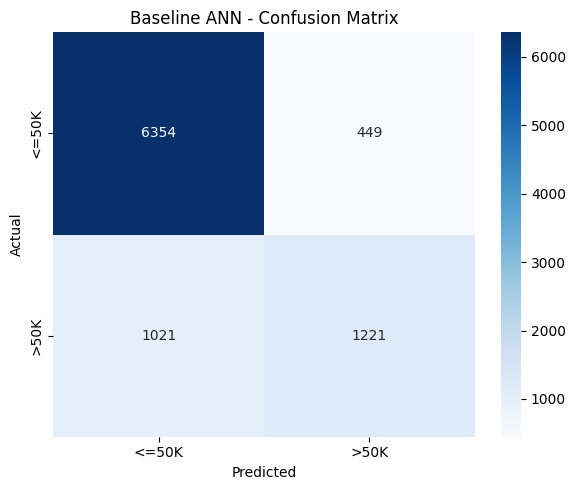

In [29]:
# Confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred_base
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)

plt.title("Baseline ANN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    "plots/baseline_confusion_matrix.png",
    dpi=150
)

plt.show()

### Observation

The diagonal cells are correct predictions; off-diagonal cells are mistakes. The lower-right cell is the number of `>50K` records correctly identified.


# Task 3 - Activation Functions

### Objective
Now I will train four separate models. I will change only the hidden activation function.

Models:
- ReLU
- Tanh
- Sigmoid
- ELU

In [30]:
# Relu model

model_relu = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

history_relu = model_relu.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8415 - loss: 0.3402 - val_accuracy: 0.8568 - val_loss: 0.3146
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.3151 - val_accuracy: 0.8546 - val_loss: 0.3132
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8551 - loss: 0.3109 - val_accuracy: 0.8543 - val_loss: 0.3135
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8567 - loss: 0.3080 - val_accuracy: 0.8554 - val_loss: 0.3136
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8580 - loss: 0.3055 - val_accuracy: 0.8530 - val_loss: 0.3146
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8591 - loss: 0.3032 - val_accuracy: 0.8530 - val_loss: 0.3154
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8608 - loss: 0.3008 - val_accuracy: 0.8543 - val_loss: 0.3156
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8613 - loss: 0.2984 - val_accuracy: 0.

### Observation

The ReLU experiment is the reference for activation comparisons. Its validation curves and class-1 F1 should be compared with the other three models.


In [31]:
# Tanh model

model_tanh = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="tanh",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

history_tanh = model_tanh.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8414 - loss: 0.3390 - val_accuracy: 0.8483 - val_loss: 0.3255
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8491 - loss: 0.3232 - val_accuracy: 0.8496 - val_loss: 0.3197
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8509 - loss: 0.3183 - val_accuracy: 0.8530 - val_loss: 0.3155
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8527 - loss: 0.3146 - val_accuracy: 0.8527 - val_loss: 0.3134
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8534 - loss: 0.3120 - val_accuracy: 0.8502 - val_loss: 0.3124
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8544 - loss: 0.3099 - val_accuracy: 0.8513 - val_loss: 0.3117
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8553 - loss: 0.3080 - val_accuracy: 0.8532 - val_loss: 0.3111
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8557 - loss: 0.3062 - val_accuracy: 0.

### Observation

Tanh outputs are bounded between -1 and 1. Inspect its validation curve and F1 against ReLU; do not assume it wins without the measured result.


In [32]:
# Sigmoid model

model_sigmoid = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="sigmoid",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

history_sigmoid = model_sigmoid.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8145 - loss: 0.3930 - val_accuracy: 0.8505 - val_loss: 0.3315
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8472 - loss: 0.3305 - val_accuracy: 0.8538 - val_loss: 0.3258
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8479 - loss: 0.3278 - val_accuracy: 0.8527 - val_loss: 0.3245
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8488 - loss: 0.3264 - val_accuracy: 0.8527 - val_loss: 0.3236
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8488 - loss: 0.3251 - val_accuracy: 0.8524 - val_loss: 0.3226
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8494 - loss: 0.3237 - val_accuracy: 0.8524 - val_loss: 0.3216
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8491 - loss: 0.3223 - val_accuracy: 0.8510 - val_loss: 0.3205
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8494 - loss: 0.3210 - val_accuracy: 0.

### Observation

The sigmoid-hidden model is included to inspect saturation and gradient flow. Use the later gradient chart to check whether the earlier layers receive smaller gradients.


In [33]:
# Elu model

model_elu = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="elu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

history_elu = model_elu.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8416 - loss: 0.3387 - val_accuracy: 0.8485 - val_loss: 0.3245
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8487 - loss: 0.3225 - val_accuracy: 0.8505 - val_loss: 0.3187
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8513 - loss: 0.3184 - val_accuracy: 0.8535 - val_loss: 0.3165
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8519 - loss: 0.3165 - val_accuracy: 0.8510 - val_loss: 0.3162
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8523 - loss: 0.3152 - val_accuracy: 0.8519 - val_loss: 0.3160
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8531 - loss: 0.3142 - val_accuracy: 0.8519 - val_loss: 0.3158
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8534 - loss: 0.3131 - val_accuracy: 0.8521 - val_loss: 0.3156
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8535 - loss: 0.3119 - val_accuracy: 0.

### Observation

ELU allows negative outputs for negative inputs. Compare its validation behavior with ReLU and Tanh; the result is dataset- and run-dependent.


In [34]:
# Compare activation functions on the validation set
activation_models = {
    "ReLU": model_relu,
    "Tanh": model_tanh,
    "Sigmoid": model_sigmoid,
    "ELU": model_elu
}

activation_rows = []
for name, model in activation_models.items():
    prob = model.predict(X_val, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    activation_rows.append({
        "Activation": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

activation_results = pd.DataFrame(activation_rows)
display(activation_results.sort_values("F1", ascending=False))

best_activation = activation_results.loc[
    activation_results["F1"].idxmax(), "Activation"
]
print(f"Observation: {best_activation} has the highest validation F1 in this run.")

,Activation,Accuracy,Precision,Recall,F1,ROC-AUC
2,Sigmoid,0.855445,0.788580,0.569677,0.661489,0.912981
3,ELU,0.849088,0.760773,0.570792,0.652229,0.906749
0,ReLU,0.837756,0.711172,0.581940,0.640098,0.886755
1,Tanh,0.843284,0.749245,0.552954,0.636305,0.901122


Observation: Sigmoid has the highest validation F1 in this run.


### Observation

This table uses the validation set for model selection. The row with the largest `F1` is the selected activation; test metrics are calculated separately in the final comparison.


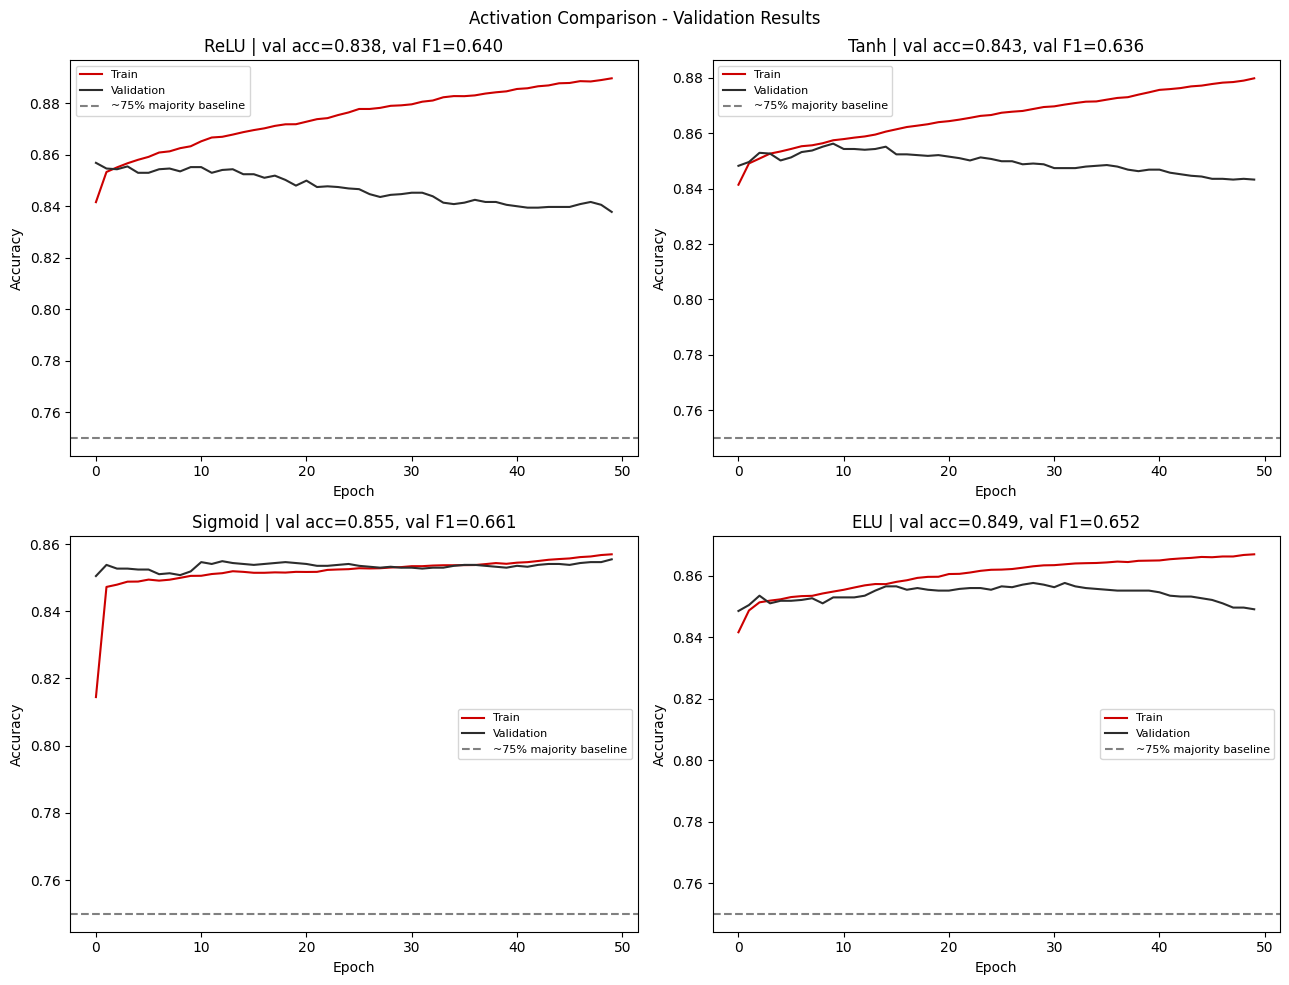

In [35]:
# 4-panel activation plot with observed validation F1

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

histories = [history_relu, history_tanh, history_sigmoid, history_elu]
models = [model_relu, model_tanh, model_sigmoid, model_elu]
names = ["ReLU", "Tanh", "Sigmoid", "ELU"]

for i, (history, model, name) in enumerate(zip(histories, models, names)):
    axes[i].plot(history.history["accuracy"], label="Train", color="#CC0000")
    axes[i].plot(history.history["val_accuracy"], label="Validation", color="#2C2C2C")
    axes[i].axhline(0.75, linestyle="--", color="gray", label="~75% majority baseline")

    val_prob = model.predict(X_val, verbose=0).ravel()
    val_pred = (val_prob > 0.5).astype(int)
    val_f1 = f1_score(y_val, val_pred, zero_division=0)
    final_val_acc = history.history["val_accuracy"][-1]

    axes[i].set_title(f"{name} | val acc={final_val_acc:.3f}, val F1={val_f1:.3f}")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Accuracy")
    axes[i].legend(fontsize=8)

plt.suptitle("Activation Comparison - Validation Results")
plt.tight_layout()
plt.savefig("plots/activation_comparison.png", dpi=150)
plt.show()

### Observation

Each panel shows train and validation accuracy with the majority-class reference. The title also prints final validation accuracy and validation F1, making the comparison more informative than accuracy alone.


Dead activation fraction: 0.5809
First-layer output shape: (500, 128)


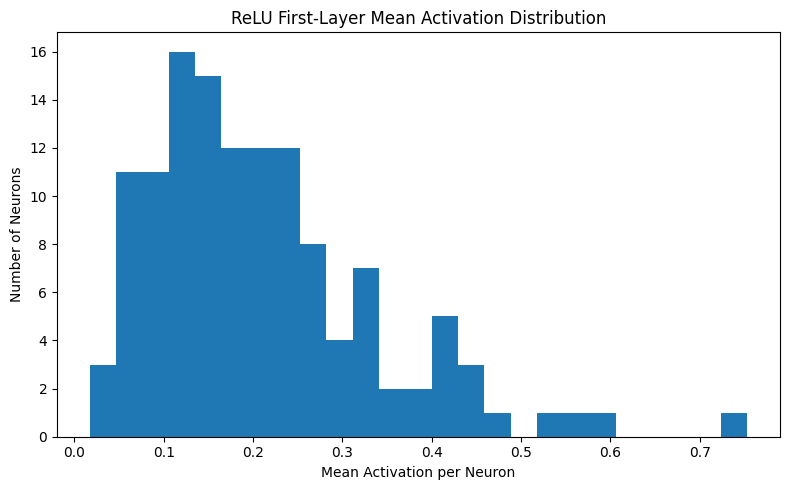

In [36]:
# ReLU dead-neuron check using the first hidden Dense layer

first_relu_layer = next(
    layer for layer in model_relu.layers
    if isinstance(layer, keras.layers.Dense)
)

X_sample = X_test.iloc[:500].to_numpy(dtype=np.float32)
weights, bias = first_relu_layer.get_weights()
relu_output = np.maximum(X_sample @ weights + bias, 0.0)

dead_fraction = float(np.mean(relu_output == 0))
print("Dead activation fraction:", round(dead_fraction, 4))
print("First-layer output shape:", relu_output.shape)

plt.figure(figsize=(8, 5))
plt.hist(relu_output.mean(axis=0), bins=25)
plt.title("ReLU First-Layer Mean Activation Distribution")
plt.xlabel("Mean Activation per Neuron")
plt.ylabel("Number of Neurons")
plt.tight_layout()
plt.savefig("plots/relu_activation_distribution.png", dpi=150)
plt.show()

### Observation

`dead_fraction` is the proportion of sampled first-layer activations equal to zero. It measures zero activations across samples and neurons; it is not by itself proof that a neuron is permanently dead.


In [37]:
# Sigmoid gradient-flow check

X_batch = tf.convert_to_tensor(
    X_train.iloc[:64].to_numpy(), dtype=tf.float32
)
y_batch = tf.convert_to_tensor(
    y_train.iloc[:64].to_numpy().reshape(-1, 1), dtype=tf.float32
)

dense_layers = [
    layer for layer in model_sigmoid.layers
    if isinstance(layer, keras.layers.Dense)
]

with tf.GradientTape(persistent=True) as tape:
    output = model_sigmoid(X_batch, training=True)
    loss_value = tf.reduce_mean(
        keras.losses.binary_crossentropy(y_batch, output)
    )

gradients = tape.gradient(loss_value, [layer.kernel for layer in dense_layers])
del tape

gradient_values = [
    float(tf.reduce_mean(tf.abs(gradient)).numpy())
    for gradient in gradients
]

for name, value in zip(["Layer 1", "Layer 2", "Output"], gradient_values):
    print(f"{name} mean |gradient|: {value:.8e}")

Layer 1 mean |gradient|: 1.49750325e-04
Layer 2 mean |gradient|: 1.60716663e-04
Output mean |gradient|: 7.03165308e-03


### Observation

The printed mean absolute gradients quantify gradients with respect to each Dense layer's kernel. Much smaller early-layer gradients than output-layer gradients are consistent with weaker backward gradient flow.


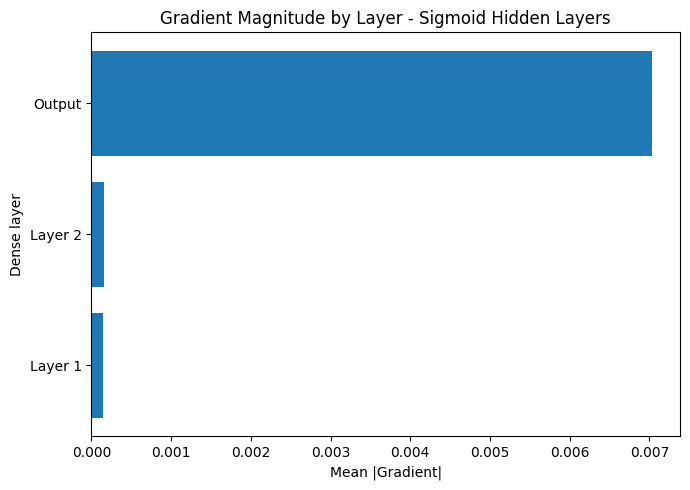

In [38]:
# Plot sigmoid gradient values as a horizontal bar chart

plt.figure(figsize=(7, 5))
plt.barh(["Layer 1", "Layer 2", "Output"], gradient_values)
plt.title("Gradient Magnitude by Layer - Sigmoid Hidden Layers")
plt.xlabel("Mean |Gradient|")
plt.ylabel("Dense layer")
plt.tight_layout()
plt.savefig("plots/sigmoid_gradient_flow.png", dpi=150)
plt.show()

### Observation

The bar chart makes layer-wise gradient magnitudes comparable. Interpret orders of magnitude, not only bar height; the sigmoid derivative is at most 0.25 and is smaller in saturated regions.


In [39]:
# Select the activation with the highest validation F1
best_activation = activation_results.loc[
    activation_results["F1"].idxmax(), "Activation"
]
best_activation_val_f1 = float(activation_results["F1"].max())

print("Best activation:", best_activation)
print("Validation F1:", round(best_activation_val_f1, 4))

Best activation: Sigmoid
Validation F1: 0.6615


In [40]:
# Record the main properties of each activation
activation_properties = {
    "ReLU": ["max(0, x)", "[0, infinity)", "No", "Lower for positive inputs", "Higher if units stay inactive"],
    "Tanh": ["tanh(x)", "(-1, 1)", "Yes", "High when saturated", "Low"],
    "Sigmoid": ["1 / (1 + exp(-x))", "(0, 1)", "No", "High when saturated; derivative <= 0.25", "Saturation can slow learning"],
    "ELU": ["x if x > 0 else alpha * (exp(x) - 1)", "(-alpha, infinity)", "Approximately", "Possible for very negative inputs", "Lower than ReLU"],
}

activation_summary = pd.DataFrame.from_dict(
    activation_properties, orient="index",
    columns=["Formula", "Output range", "Zero-centred", "Vanishing-gradient risk", "Dead-neuron risk"]
).rename_axis("Activation").reset_index()

In [41]:
# Add the measured validation accuracy to the reference table
validation_accuracy = activation_results.set_index("Activation")["Accuracy"]
activation_summary["Validation accuracy"] = activation_summary["Activation"].map(validation_accuracy)

activation_summary.loc[len(activation_summary)] = [
    "Sigmoid (output only)", "1 / (1 + exp(-x))", "(0, 1)", "No",
    "Possible saturation; BCE is suitable for binary classification",
    "Not applicable", np.nan
]

display(activation_summary.round(4))

,Activation,Formula,Output range,Zero-centred,Vanishing-gradient risk,Dead-neuron risk,Validation accuracy
0,ReLU,"max(0, x)","[0, infinity)",No,Lower for positive inputs,Higher if units stay inactive,0.8378
1,Tanh,tanh(x),"(-1, 1)",Yes,High when saturated,Low,0.8433
2,Sigmoid,1 / (1 + exp(-x)),"(0, 1)",No,High when saturated; derivative <= 0.25,Saturation can slow learning,0.8554
3,ELU,x if x > 0 else alpha * (exp(x) - 1),"(-alpha, infinity)",Approximately,Possible for very negative inputs,Lower than ReLU,0.8491
4,Sigmoid (output only),1 / (1 + exp(-x)),"(0, 1)",No,Possible saturation; BCE is suitable for binar...,Not applicable,NaN


### Observation

The selected activation is the one with the highest validation F1 in the table. The exact winner is determined by the actual run output, not preset in the notebook.


# Task 4 - Weight Initialization

### Objective
I will compare five different ways of starting the network weights:
- Glorot Uniform
- Glorot Normal
- He Uniform
- He Normal
- Zeros

### Initialization reference

| Method | Variance idea | Common use |
|---|---|---|
| Glorot / Xavier | `2 / (fan_in + fan_out)` | Tanh or sigmoid networks |
| He | `2 / fan_in` | ReLU-family activations |
| Zeros | All weights start at `0` | Included to demonstrate symmetry failure |

When every weight starts at zero, neurons in the same layer start identically and may learn the same features. Random initialization gives hidden neurons different starting points.

In [42]:
# Glorot Uniform initialization model

model_glorot_uniform = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)
glorot_uniform_initial_weights = next(
    layer for layer in model_glorot_uniform.layers
    if isinstance(layer, keras.layers.Dense)
).get_weights()[0].copy()

history_glorot_uniform = model_glorot_uniform.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8436 - loss: 0.3371 - val_accuracy: 0.8521 - val_loss: 0.3149
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8530 - loss: 0.3154 - val_accuracy: 0.8532 - val_loss: 0.3128
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8548 - loss: 0.3113 - val_accuracy: 0.8530 - val_loss: 0.3127
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8569 - loss: 0.3080 - val_accuracy: 0.8532 - val_loss: 0.3127
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8578 - loss: 0.3051 - val_accuracy: 0.8543 - val_loss: 0.3128
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8586 - loss: 0.3025 - val_accuracy: 0.8543 - val_loss: 0.3136
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8607 - loss: 0.3000 - val_accuracy: 0.8546 - val_loss: 0.3143
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8616 - loss: 0.2976 - val_accuracy: 0.

### Observation

Glorot Uniform starts the hidden-layer weights from a bounded random distribution. The actual validation curve shows whether that initialization converges effectively in this run.


In [43]:
# Glorot Normal initialization model

model_glorot_normal = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="glorot_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)
history_glorot_normal = model_glorot_normal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8455 - loss: 0.3324 - val_accuracy: 0.8538 - val_loss: 0.3154
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8525 - loss: 0.3145 - val_accuracy: 0.8546 - val_loss: 0.3136
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8549 - loss: 0.3106 - val_accuracy: 0.8541 - val_loss: 0.3128
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8568 - loss: 0.3074 - val_accuracy: 0.8546 - val_loss: 0.3129
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8585 - loss: 0.3044 - val_accuracy: 0.8549 - val_loss: 0.3130
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8598 - loss: 0.3016 - val_accuracy: 0.8563 - val_loss: 0.3134
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8615 - loss: 0.2987 - val_accuracy: 0.8563 - val_loss: 0.3145
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8631 - loss: 0.2958 - val_accuracy: 0.

### Observation

Glorot Normal uses normally distributed initial weights. Compare its validation curve with Glorot Uniform while keeping the architecture and other training settings fixed.


In [44]:
# He Uniform initialization model

model_he_uniform = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_uniform",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)
history_he_uniform = model_he_uniform.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8372 - loss: 0.3446 - val_accuracy: 0.8554 - val_loss: 0.3150
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8533 - loss: 0.3155 - val_accuracy: 0.8541 - val_loss: 0.3135
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8544 - loss: 0.3113 - val_accuracy: 0.8543 - val_loss: 0.3132
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8567 - loss: 0.3081 - val_accuracy: 0.8549 - val_loss: 0.3130
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8581 - loss: 0.3054 - val_accuracy: 0.8554 - val_loss: 0.3132
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8593 - loss: 0.3027 - val_accuracy: 0.8557 - val_loss: 0.3136
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8599 - loss: 0.3002 - val_accuracy: 0.8563 - val_loss: 0.3141
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8609 - loss: 0.2977 - val_accuracy: 0.

### Observation

He Uniform is designed to support ReLU networks by accounting for the activation's effect on signal variance. Judge it by the validation trajectory and F1 table.


In [45]:
# He Normal initialization model

model_he_normal = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)
he_normal_initial_weights = next(
    layer for layer in model_he_normal.layers
    if isinstance(layer, keras.layers.Dense)
).get_weights()[0].copy()

history_he_normal = model_he_normal.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8440 - loss: 0.3357 - val_accuracy: 0.8546 - val_loss: 0.3155
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8524 - loss: 0.3153 - val_accuracy: 0.8521 - val_loss: 0.3127
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8547 - loss: 0.3112 - val_accuracy: 0.8535 - val_loss: 0.3124
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8563 - loss: 0.3080 - val_accuracy: 0.8546 - val_loss: 0.3128
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8579 - loss: 0.3051 - val_accuracy: 0.8552 - val_loss: 0.3129
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8597 - loss: 0.3025 - val_accuracy: 0.8541 - val_loss: 0.3128
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8611 - loss: 0.2998 - val_accuracy: 0.8546 - val_loss: 0.3128
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8627 - loss: 0.2972 - val_accuracy: 0.

### Observation

The He Normal model's first-layer weights are saved before fitting, so the later histogram compares the same model's true initial weights with its trained weights.


In [46]:
# Zeros initialization model

model_zeros = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="zeros",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)
history_zeros = model_zeros.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7522 - loss: 0.6447 - val_accuracy: 0.7521 - val_loss: 0.6071
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7522 - loss: 0.5873 - val_accuracy: 0.7521 - val_loss: 0.5733
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7522 - loss: 0.5669 - val_accuracy: 0.7521 - val_loss: 0.5629
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7522 - loss: 0.5613 - val_accuracy: 0.7521 - val_loss: 0.5605
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7522 - loss: 0.5601 - val_accuracy: 0.7521 - val_loss: 0.5601
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7522 - loss: 0.5600 - val_accuracy: 0.7521 - val_loss: 0.5600
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7522 - loss: 0.5600 - val_accuracy: 0.7521 - val_loss: 0.5600
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7522 - loss: 0.5600 - val_accuracy: 0.

### Observation

Zero initialization deliberately creates identical hidden-layer starting weights. Compare its accuracy and loss curves with random initializers to see whether it learns beyond the majority-class baseline.


In [47]:
# Compare all five initializers using validation F1

init_models = [
    model_glorot_uniform,
    model_glorot_normal,
    model_he_uniform,
    model_he_normal,
    model_zeros
]
init_names = ["Glorot Uniform", "Glorot Normal", "He Uniform", "He Normal", "Zeros"]
init_f1_scores = []

for model in init_models:
    prob = model.predict(X_val, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    init_f1_scores.append(f1_score(y_val, pred, zero_division=0))

initializer_results = pd.DataFrame({
    "Initializer": init_names,
    "Validation F1": init_f1_scores
})

display(initializer_results.sort_values("Validation F1", ascending=False))
print("Initializer selection uses validation data; test data is reserved for final evaluation.")

,Initializer,Validation F1
2,He Uniform,0.648137
0,Glorot Uniform,0.626223
1,Glorot Normal,0.624131
3,He Normal,0.623492
4,Zeros,0.000000


Initializer selection uses validation data; test data is reserved for final evaluation.


### Observation

The initializer table reports validation F1 for all five methods. The highest validation F1 determines the selected initializer; test data is not used to select it.


Glorot Uniform first reached 82% validation accuracy at epoch 1.
Glorot Normal first reached 82% validation accuracy at epoch 1.
He Uniform first reached 82% validation accuracy at epoch 1.
He Normal first reached 82% validation accuracy at epoch 1.


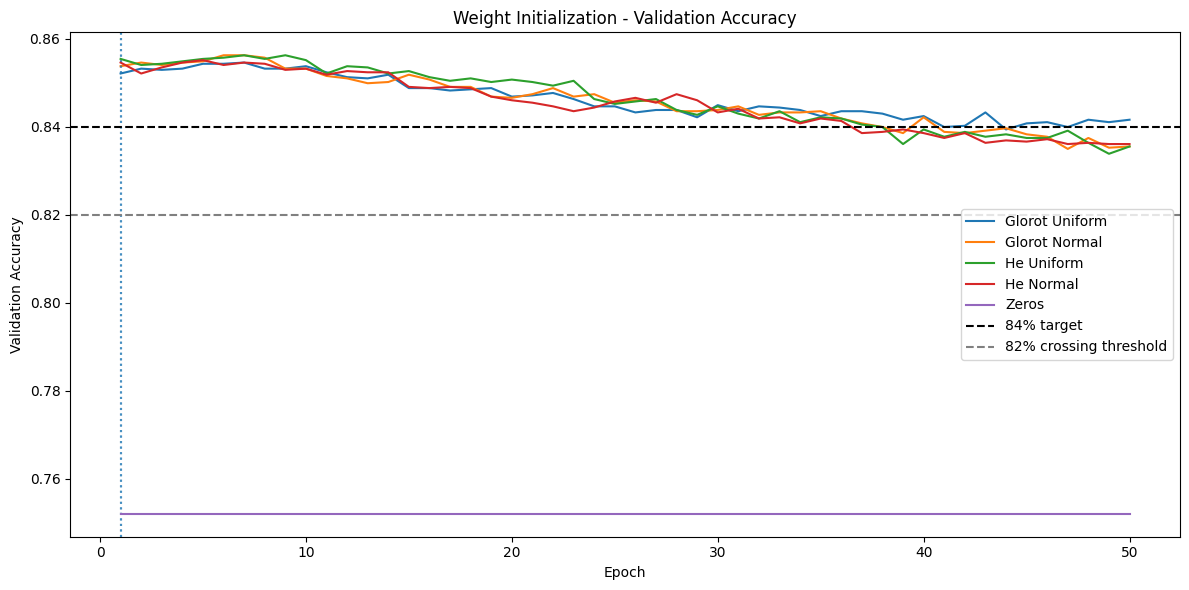

In [48]:
# Initializer convergence comparison and epoch-to-82% markers

plt.figure(figsize=(12, 6))
init_histories = [
    ("Glorot Uniform", history_glorot_uniform),
    ("Glorot Normal", history_glorot_normal),
    ("He Uniform", history_he_uniform),
    ("He Normal", history_he_normal),
    ("Zeros", history_zeros)
]

for name, history in init_histories:
    val_accuracy = np.asarray(history.history["val_accuracy"])
    plt.plot(np.arange(1, len(val_accuracy) + 1), val_accuracy, label=name)
    if name != "Zeros":
        crossing = np.flatnonzero(val_accuracy >= 0.82)
        if len(crossing):
            epoch = int(crossing[0] + 1)
            plt.axvline(epoch, linestyle=":", alpha=0.35)
            print(f"{name} first reached 82% validation accuracy at epoch {epoch}.")
        else:
            print(f"{name} did not reach 82% validation accuracy in this run.")

plt.axhline(0.84, linestyle="--", color="black", label="84% target")
plt.axhline(0.82, linestyle="--", color="gray", label="82% crossing threshold")
plt.title("Weight Initialization - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("plots/initialiser_convergence.png", dpi=150)
plt.show()

### Observation

The horizontal 84% line is the target benchmark and the 82% line is the crossing threshold. Printed messages identify the first epoch crossing 82%, or state that no crossing occurred.


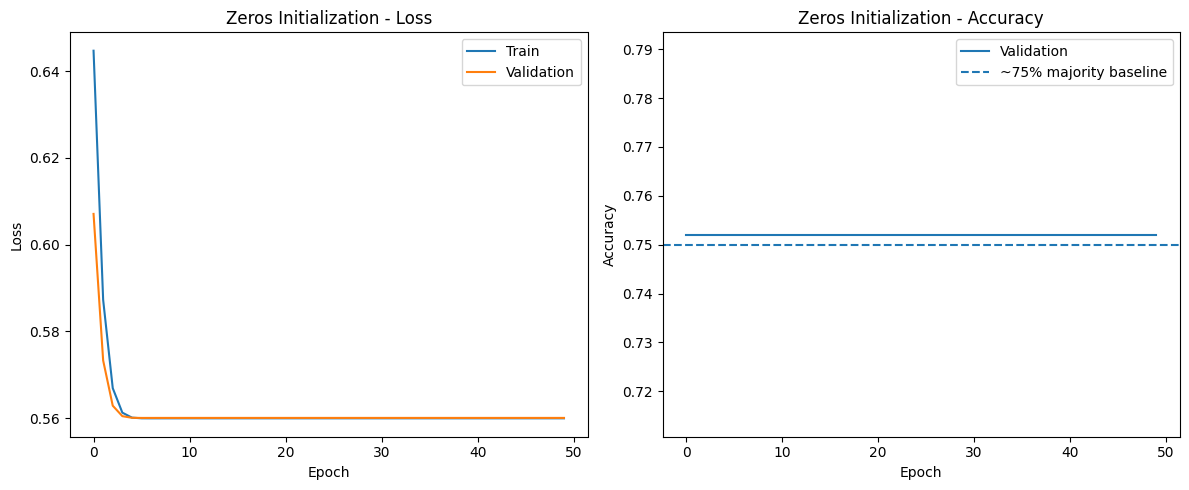

In [49]:
# Show how the all-zero initializer behaves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history_zeros.history["loss"], label="Train")
axes[0].plot(history_zeros.history["val_loss"], label="Validation")
axes[0].set_title("Zeros Initialization - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_zeros.history["val_accuracy"], label="Validation")
axes[1].axhline(0.75, linestyle="--", label="~75% majority baseline")
axes[1].set_title("Zeros Initialization - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("plots/zeros_failure.png", dpi=150)
plt.show()

### Observation

The zero-initialized loss and accuracy curves show whether the network is learning useful distinctions. A flat accuracy near the majority baseline is consistent with the symmetry problem, but report what the run actually shows.


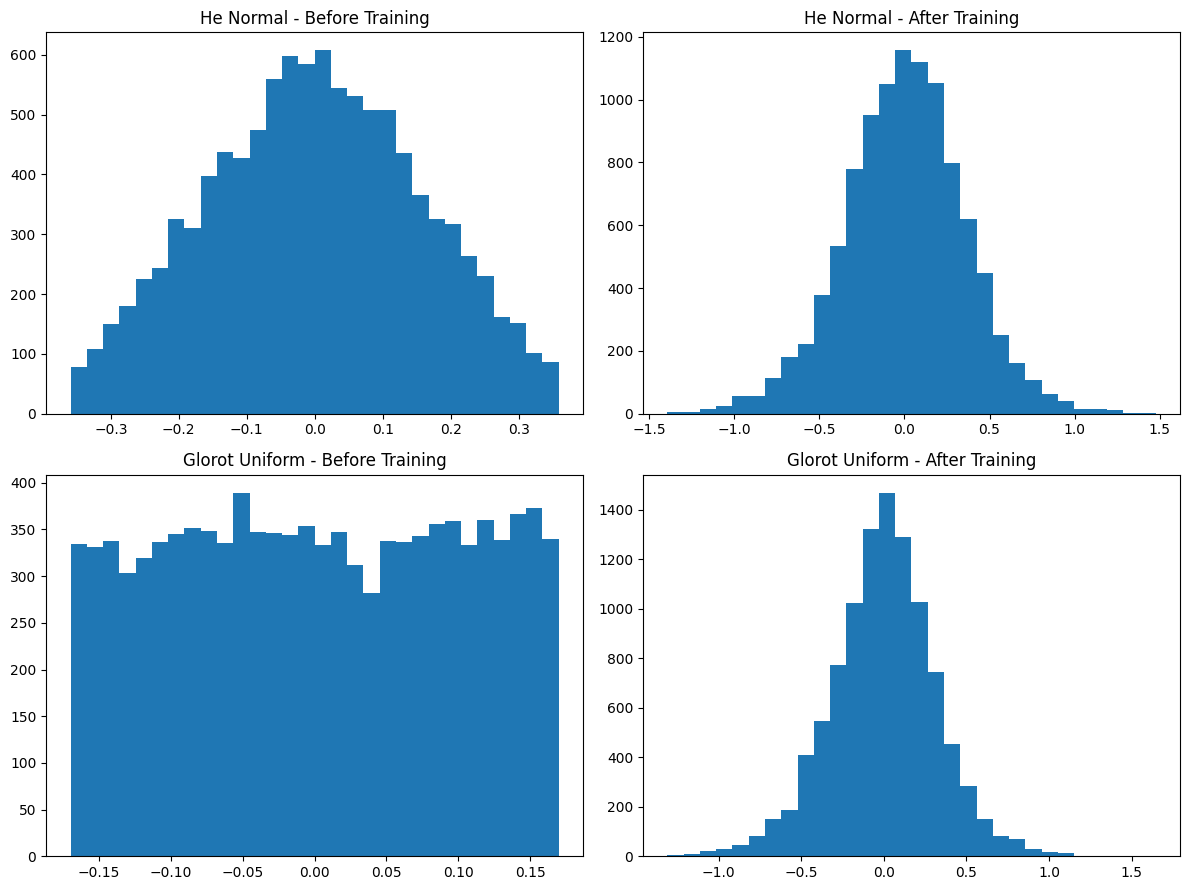

In [50]:
# Initial and trained weight distributions from the same models

he_normal_trained_weights = next(
    layer for layer in model_he_normal.layers
    if isinstance(layer, keras.layers.Dense)
).get_weights()[0]
glorot_uniform_trained_weights = next(
    layer for layer in model_glorot_uniform.layers
    if isinstance(layer, keras.layers.Dense)
).get_weights()[0]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].hist(he_normal_initial_weights.flatten(), bins=30)
axes[0, 0].set_title("He Normal - Before Training")
axes[0, 1].hist(he_normal_trained_weights.flatten(), bins=30)
axes[0, 1].set_title("He Normal - After Training")
axes[1, 0].hist(glorot_uniform_initial_weights.flatten(), bins=30)
axes[1, 0].set_title("Glorot Uniform - Before Training")
axes[1, 1].hist(glorot_uniform_trained_weights.flatten(), bins=30)
axes[1, 1].set_title("Glorot Uniform - After Training")

plt.tight_layout()
plt.savefig("plots/weight_distributions.png", dpi=150)
plt.show()

### Observation

The `Before Training` histograms use the weights saved directly after model construction; `After Training` uses the corresponding model's fitted weights. Changes in spread/shape show how gradient updates altered the starting distribution.


In [51]:
# Select the best initializer by validation F1

best_initializer = initializer_results.loc[
    initializer_results["Validation F1"].idxmax(), "Initializer"
]
best_initializer_val_f1 = float(initializer_results["Validation F1"].max())

print("Best initializer by validation F1:", best_initializer)
print("Best initializer validation F1:", round(best_initializer_val_f1, 4))

Best initializer by validation F1: He Uniform
Best initializer validation F1: 0.6481


### Observation

The chosen initializer is the row with the largest validation F1. The final test result for that selected model appears in the full results table.


# Task 5 - Loss Functions

### Objective
I will compare BCE, MSE, Weighted BCE and Focal Loss.

The main focus will be the F1-score of the `>50K` class.

In [52]:
# MSE model: same architecture, different loss

model_mse = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="mean_squared_error"
)

mse_f1_callback = ValidationF1Callback(X_val, y_val)
history_mse = model_mse.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[mse_f1_callback],
    verbose=1
)

mse_val_prob = model_mse.predict(X_val, verbose=0).ravel()
mse_val_pred = (mse_val_prob > 0.5).astype(int)
mse_val_f1 = f1_score(y_val, mse_val_pred, zero_division=0)

# Separate test metrics are reported only after the comparison settings are fixed.
y_prob_mse = model_mse.predict(X_test, verbose=0).ravel()
y_pred_mse = (y_prob_mse > 0.5).astype(int)
mse_f1 = f1_score(y_test, y_pred_mse, zero_division=0)
print("MSE validation F1:", round(mse_val_f1, 4))
print("MSE test F1 (reported, not used for selection):", round(mse_f1, 4))

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8449 - loss: 0.1076 - val_accuracy: 0.8507 - val_loss: 0.1017
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8553 - loss: 0.1010 - val_accuracy: 0.8513 - val_loss: 0.1009
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8569 - loss: 0.0995 - val_accuracy: 0.8535 - val_loss: 0.1007
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8588 - loss: 0.0982 - val_accuracy: 0.8563 - val_loss: 0.1004
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8601 - loss: 0.0971 - val_accuracy: 0.8563 - val_loss: 0.1003
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8618 - loss: 0.0961 - val_accuracy: 0.8538 - val_loss: 0.1004
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8630 - loss: 0.0952 - val_accuracy: 0.8532 - val_loss: 0.1004
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8641 - loss: 0.0944 - val_accuracy: 0.

### Observation

This experiment changes the loss to MSE while retaining the sigmoid output. Compare its validation-F1 trajectory with BCE rather than concluding from training loss values alone.


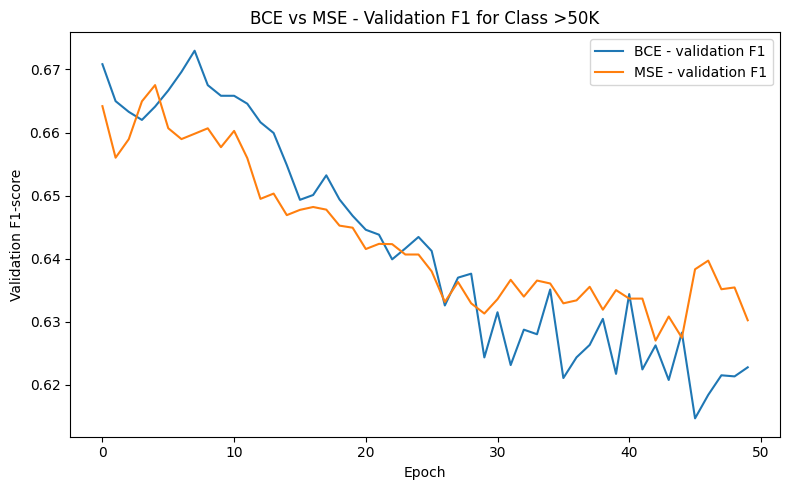

Final BCE validation F1: 0.6228
Final MSE validation F1: 0.6302


In [53]:
# BCE vs MSE validation F1 by epoch

plt.figure(figsize=(8, 5))
plt.plot(base_f1_callback.values, label="BCE - validation F1")
plt.plot(mse_f1_callback.values, label="MSE - validation F1")
plt.title("BCE vs MSE - Validation F1 for Class >50K")
plt.xlabel("Epoch")
plt.ylabel("Validation F1-score")
plt.legend()
plt.tight_layout()
plt.savefig("plots/loss_f1_comparison.png", dpi=150)
plt.show()
print("Final BCE validation F1:", round(base_f1_callback.values[-1], 4))
print("Final MSE validation F1:", round(mse_f1_callback.values[-1], 4))

### Observation

The graph now plots per-epoch validation F1 for the `>50K` class, as required. Compare the final values and the shape/stability of the two curves.


In [54]:
# Calculate balanced class weights from the training labels
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)
class_weight_dict = {
    0: float(class_weights[0]),
    1: float(class_weights[1])
}
print("Class weights:", class_weight_dict)

Class weights: {0: 0.6647407104940792, 1: 2.017536249845086}


In [55]:
# Train the weighted BCE model
model_wbce = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss="binary_crossentropy"
)

history_wbce = model_wbce.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7979 - loss: 0.3951 - val_accuracy: 0.8126 - val_loss: 0.3735
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8114 - loss: 0.3720 - val_accuracy: 0.8162 - val_loss: 0.3670
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8150 - loss: 0.3663 - val_accuracy: 0.8198 - val_loss: 0.3622
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8166 - loss: 0.3619 - val_accuracy: 0.8217 - val_loss: 0.3603
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8181 - loss: 0.3580 - val_accuracy: 0.8237 - val_loss: 0.3595
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8194 - loss: 0.3543 - val_accuracy: 0.8248 - val_loss: 0.3589
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8210 - loss: 0.3509 - val_accuracy: 0.8223 - val_loss: 0.3577
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8230 - loss: 0.3477 - val_accuracy: 0.

In [56]:
# Validation metrics guide the comparison; test metrics are for reporting
wbce_val_prob = model_wbce.predict(X_val, verbose=0).ravel()
wbce_val_pred = (wbce_val_prob > 0.5).astype(int)
wbce_val_precision = precision_score(y_val, wbce_val_pred, zero_division=0)
wbce_val_recall = recall_score(y_val, wbce_val_pred, zero_division=0)
wbce_val_f1 = f1_score(y_val, wbce_val_pred, zero_division=0)

# Held-out test metrics
y_prob_wbce = model_wbce.predict(X_test, verbose=0).ravel()
y_pred_wbce = (y_prob_wbce > 0.5).astype(int)
wbce_precision = precision_score(y_test, y_pred_wbce, zero_division=0)
wbce_recall = recall_score(y_test, y_pred_wbce, zero_division=0)
wbce_f1 = f1_score(y_test, y_pred_wbce, zero_division=0)

print("Validation Precision:", round(wbce_val_precision, 4))
print("Validation Recall   :", round(wbce_val_recall, 4))
print("Validation F1       :", round(wbce_val_f1, 4))
print("Test Precision      :", round(wbce_precision, 4))
print("Test Recall         :", round(wbce_recall, 4))
print("Test F1             :", round(wbce_f1, 4))

Validation Precision: 0.5976
Validation Recall   : 0.7614
Validation F1       : 0.6696
Test Precision      : 0.6095
Test Recall         : 0.7471
Test F1             : 0.6713


### Observation

The printed class weights show how much more strongly minority-class mistakes are weighted. Compare validation Recall and F1 with the unweighted baseline to see the effect.


,Model,Precision,Recall,F1
0,Baseline,0.731138,0.544603,0.624233
1,Weighted BCE,0.609534,0.747101,0.671343


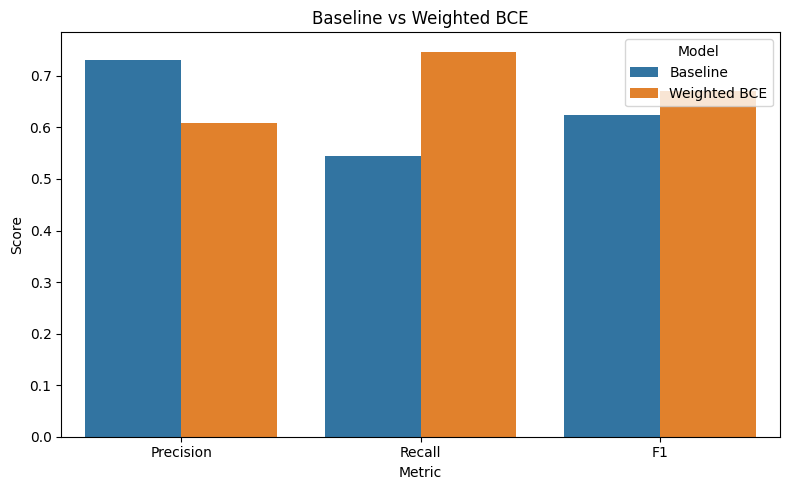

In [57]:
# Baseline vs Weighted BCE metrics

metric_table = pd.DataFrame({
    "Model": ["Baseline", "Weighted BCE"],
    "Precision": [base_precision, wbce_precision],
    "Recall": [base_recall, wbce_recall],
    "F1": [base_f1, wbce_f1]
})

display(metric_table)

metric_melt = metric_table.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=metric_melt,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Baseline vs Weighted BCE")
plt.tight_layout()

plt.savefig(
    "plots/weighted_bce_metrics.png",
    dpi=150
)

plt.show()

### Observation

The grouped bars show the test-set reporting metrics for baseline and Weighted BCE. Higher Recall can come with lower Precision, so interpret all three metrics together; selection itself uses validation F1.


In [58]:
# Focal loss puts less weight on easy examples
gamma = 2.0
alpha = 0.25

def focal_loss_value(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    y_true = tf.cast(tf.reshape(y_true, tf.shape(y_pred)), y_pred.dtype)

    bce = -y_true * tf.math.log(y_pred)
    bce -= (1.0 - y_true) * tf.math.log(1.0 - y_pred)

    weights = (
        alpha * y_true * tf.pow(1.0 - y_pred, gamma)
        + (1.0 - alpha) * (1.0 - y_true) * tf.pow(y_pred, gamma)
    )
    return tf.reduce_mean(weights * bce)

In [59]:
# Train the focal-loss model
model_focal = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=False,
    optimizer="adam",
    loss=focal_loss_value
)

history_focal = model_focal.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8176 - loss: 0.0356 - val_accuracy: 0.8250 - val_loss: 0.0328
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8276 - loss: 0.0327 - val_accuracy: 0.8281 - val_loss: 0.0325
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8306 - loss: 0.0321 - val_accuracy: 0.8286 - val_loss: 0.0324
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8321 - loss: 0.0317 - val_accuracy: 0.8256 - val_loss: 0.0324
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8334 - loss: 0.0313 - val_accuracy: 0.8242 - val_loss: 0.0324
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8355 - loss: 0.0310 - val_accuracy: 0.8239 - val_loss: 0.0325
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8370 - loss: 0.0306 - val_accuracy: 0.8237 - val_loss: 0.0326
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8381 - loss: 0.0303 - val_accuracy: 0.

In [60]:
# Compare focal loss on validation data, then report test metrics
focal_val_prob = model_focal.predict(X_val, verbose=0).ravel()
focal_val_pred = (focal_val_prob > 0.5).astype(int)
focal_val_precision = precision_score(y_val, focal_val_pred, zero_division=0)
focal_val_recall = recall_score(y_val, focal_val_pred, zero_division=0)
focal_val_f1 = f1_score(y_val, focal_val_pred, zero_division=0)

# Keep these variables for the final comparison table and ROC curve
y_prob_focal = model_focal.predict(X_test, verbose=0).ravel()
y_pred_focal = (y_prob_focal > 0.5).astype(int)
focal_precision = precision_score(y_test, y_pred_focal, zero_division=0)
focal_recall = recall_score(y_test, y_pred_focal, zero_division=0)
focal_f1 = f1_score(y_test, y_pred_focal, zero_division=0)

print("Validation Precision:", round(focal_val_precision, 4))
print("Validation Recall   :", round(focal_val_recall, 4))
print("Validation F1       :", round(focal_val_f1, 4))
print("Test F1             :", round(focal_f1, 4))

Validation Precision: 0.8222
Validation Recall   : 0.3969
Validation F1       : 0.5353
Test F1             : 0.5159


### Observation

The focal-loss model emphasizes hard examples using the `gamma` factor and adjusts class weighting with `alpha`. Check the printed validation F1 and compare it with BCE and Weighted BCE.


In [61]:
# Loss function summary using validation F1

loss_table = pd.DataFrame({
    "Loss": ["Binary Cross-Entropy", "Weighted BCE", "MSE", "Focal Loss"],
    "Simplified formula": [
        "-[y log(p) + (1-y) log(1-p)]",
        "BCE weighted by class importance",
        "(y-p)^2",
        "Focal weight × BCE"
    ],
    "Best for": [
        "Binary classification",
        "Binary classification with unequal class costs",
        "Regression; included here as a comparison",
        "Focusing more on difficult examples"
    ],
    "Imbalance handling": [
        "No explicit weighting",
        "Higher loss weight for minority-class examples",
        "No explicit weighting",
        "Down-weights easy examples; alpha balances classes"
    ],
    "Validation F1 (class 1)": [
        float(base_val_f1), float(wbce_val_f1), float(mse_val_f1), float(focal_val_f1)
    ]
})
display(loss_table.round(4))

,Loss,Simplified formula,Best for,Imbalance handling,Validation F1 (class 1)
0,Binary Cross-Entropy,-[y log(p) + (1-y) log(1-p)],Binary classification,No explicit weighting,0.6228
1,Weighted BCE,BCE weighted by class importance,Binary classification with unequal class costs,Higher loss weight for minority-class examples,0.6696
2,MSE,(y-p)^2,Regression; included here as a comparison,No explicit weighting,0.6302
3,Focal Loss,Focal weight × BCE,Focusing more on difficult examples,Down-weights easy examples; alpha balances cla...,0.5353


### Observation

The table includes formula, use case, imbalance handling and validation F1. The recommended loss should be chosen from validation results plus the intended cost of false negatives/false positives, not a presumed winner.


# Task 6 - Batch Normalization

### Objective
I will add Batch Normalization to the ANN and compare it with the baseline.

### Batch Normalization reference

BatchNorm normalizes mini-batch activations during training and uses moving averages at inference. Its learned parameters are `gamma` (scale) and `beta` (shift):

`BN(x) = gamma * (x - batch_mean) / sqrt(batch_variance + epsilon) + beta`

The preferred order in this project is `Dense -> BatchNormalization -> Activation`.

In [62]:
# Batch Normalization model: Dense -> BatchNorm -> Activation

model_bn = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="adam",
    loss="binary_crossentropy"
)
model_bn.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

### Observation

`model.summary()` should show BatchNormalization after each Dense layer and before the activation. It also distinguishes trainable parameters (`gamma`, `beta`) from non-trainable running statistics.


In [63]:
# Train BatchNorm model

history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8197 - loss: 0.3789 - val_accuracy: 0.8499 - val_loss: 0.3191
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8514 - loss: 0.3199 - val_accuracy: 0.8455 - val_loss: 0.3168
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8549 - loss: 0.3123 - val_accuracy: 0.8483 - val_loss: 0.3163
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8577 - loss: 0.3068 - val_accuracy: 0.8505 - val_loss: 0.3168
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8595 - loss: 0.3021 - val_accuracy: 0.8488 - val_loss: 0.3184
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8617 - loss: 0.2977 - val_accuracy: 0.8494 - val_loss: 0.3187
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8640 - loss: 0.2934 - val_accuracy: 0.8460 - val_loss: 0.3202
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8665 - loss: 0.2895 - val_accuracy: 0.

In [64]:
y_prob_bn_val = model_bn.predict(X_val, verbose=0).ravel()
y_pred_bn_val = (y_prob_bn_val > 0.5).astype(int)
bn_val_f1 = f1_score(y_val, y_pred_bn_val, zero_division=0)

# Test metrics are for final reporting only.
y_prob_bn = model_bn.predict(X_test, verbose=0).ravel()
y_pred_bn = (y_prob_bn > 0.5).astype(int)

bn_accuracy = accuracy_score(y_test, y_pred_bn)
bn_precision = precision_score(y_test, y_pred_bn, zero_division=0)
bn_recall = recall_score(y_test, y_pred_bn, zero_division=0)
bn_f1 = f1_score(y_test, y_pred_bn, zero_division=0)
bn_auc = roc_auc_score(y_test, y_prob_bn)

print("Validation F1 (for analysis):", round(bn_val_f1, 4))
print("Accuracy :", bn_accuracy)
print("Precision:", bn_precision)
print("Recall   :", bn_recall)
print("F1       :", bn_f1)
print("ROC-AUC  :", bn_auc)

Validation F1 (for analysis): 0.5861
Accuracy : 0.8237700386954119
Precision: 0.7098445595854922
Recall   : 0.4888492417484389
F1       : 0.5789751716851559
ROC-AUC  : 0.870675003930548


### Observation

The printed test metrics summarize BatchNorm performance, while `bn_val_f1` is retained for fair comparison and impact analysis. Compare both against the baseline without using test scores to select the configuration.


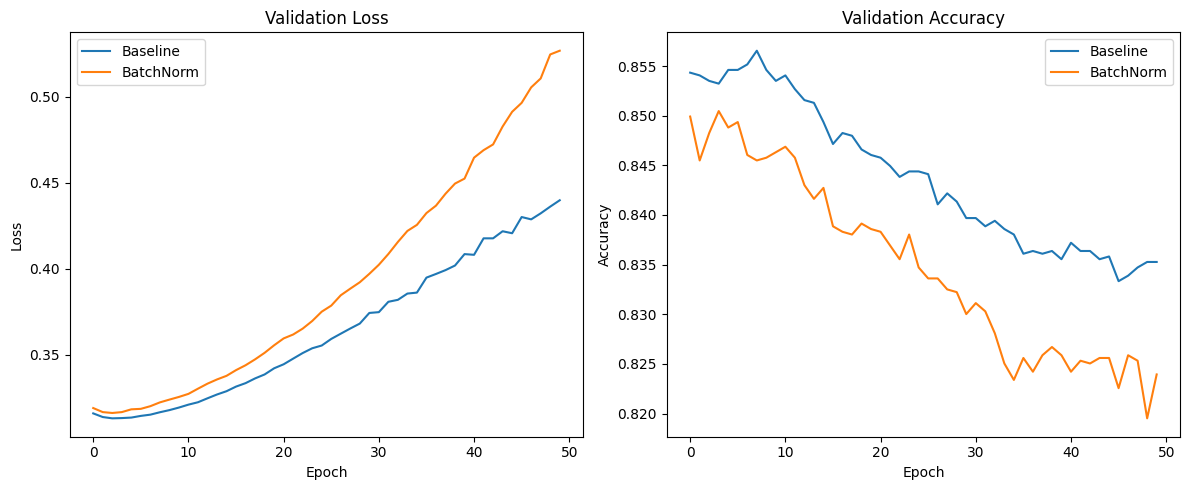

Compare the curves rather than assuming BatchNorm must improve this run.


In [65]:
# Compare training dynamics with and without BatchNorm
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, title, label in [
    (axes[0], "val_loss", "Validation Loss", "Loss"),
    (axes[1], "val_accuracy", "Validation Accuracy", "Accuracy")
]:
    ax.plot(history_base.history[metric], label="Baseline")
    ax.plot(history_bn.history[metric], label="BatchNorm")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend()

plt.tight_layout()
plt.savefig("plots/batchnorm_dynamics.png", dpi=150)
plt.show()
print("Compare the curves rather than assuming BatchNorm must improve this run.")

### Observation

Compare the first 30 epochs where needed and inspect validation loss/accuracy together. BatchNorm may improve convergence, but the result must be read from these curves rather than assumed.


In [66]:
# BatchNorm after activation (position experiment)

model_bn_after = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(64, activation="relu", kernel_initializer="he_normal"),
    keras.layers.BatchNormalization(),
    keras.layers.Dense(1, activation="sigmoid")
])

model_bn_after.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_bn_after = model_bn_after.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8277 - loss: 0.3711 - val_accuracy: 0.8494 - val_loss: 0.3266
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8509 - loss: 0.3180 - val_accuracy: 0.8510 - val_loss: 0.3219
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8554 - loss: 0.3089 - val_accuracy: 0.8483 - val_loss: 0.3218
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8584 - loss: 0.3025 - val_accuracy: 0.8485 - val_loss: 0.3236
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8619 - loss: 0.2971 - val_accuracy: 0.8460 - val_loss: 0.3251
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8644 - loss: 0.2915 - val_accuracy: 0.8460 - val_loss: 0.3299
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8668 - loss: 0.2863 - val_accuracy: 0.8438 - val_loss: 0.3328
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8692 - loss: 0.2810 - val_accuracy: 0.

### Observation

This is the alternate `Dense(ReLU) -> BatchNorm` order. Its validation curve is compared with the canonical `Dense -> BatchNorm -> ReLU` experiment.


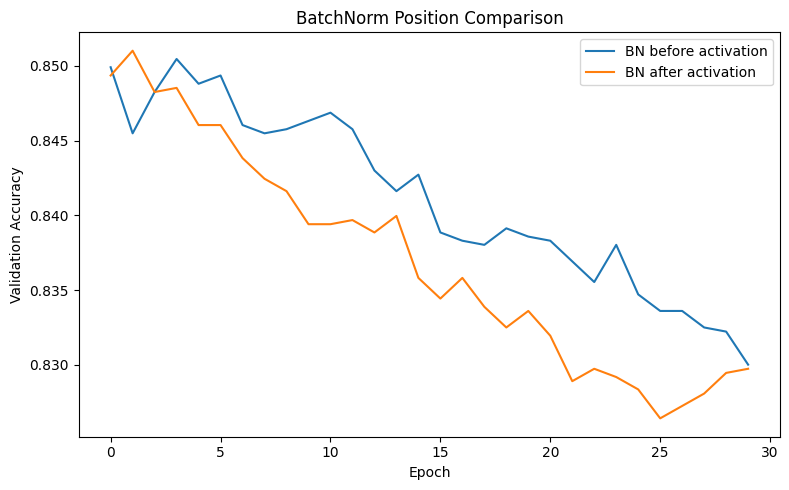

In [67]:
# Compare the two BatchNorm positions

plt.figure(figsize=(8, 5))

plt.plot(
    history_bn.history["val_accuracy"][:30],
    label="BN before activation"
)

plt.plot(
    history_bn_after.history["val_accuracy"],
    label="BN after activation"
)

plt.title("BatchNorm Position Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.tight_layout()

plt.savefig(
    "plots/batchnorm_position.png",
    dpi=150
)

plt.show()

### Observation

The graph compares the first 30 epochs for both positions. A single run indicates an observed difference only; it does not establish statistical significance.


In [68]:
# Read the learned scale and shift values from the first BatchNorm layer
bn_layer = next(
    layer for layer in model_bn.layers
    if isinstance(layer, keras.layers.BatchNormalization)
)
gamma, beta, moving_mean, moving_var = bn_layer.get_weights()

print("Gamma shape:", gamma.shape)
print("Beta shape :", beta.shape)
print("Neurons with |gamma| < 0.1:", int(np.sum(np.abs(gamma) < 0.1)))

Gamma shape: (128,)
Beta shape : (128,)
Neurons with |gamma| < 0.1: 0


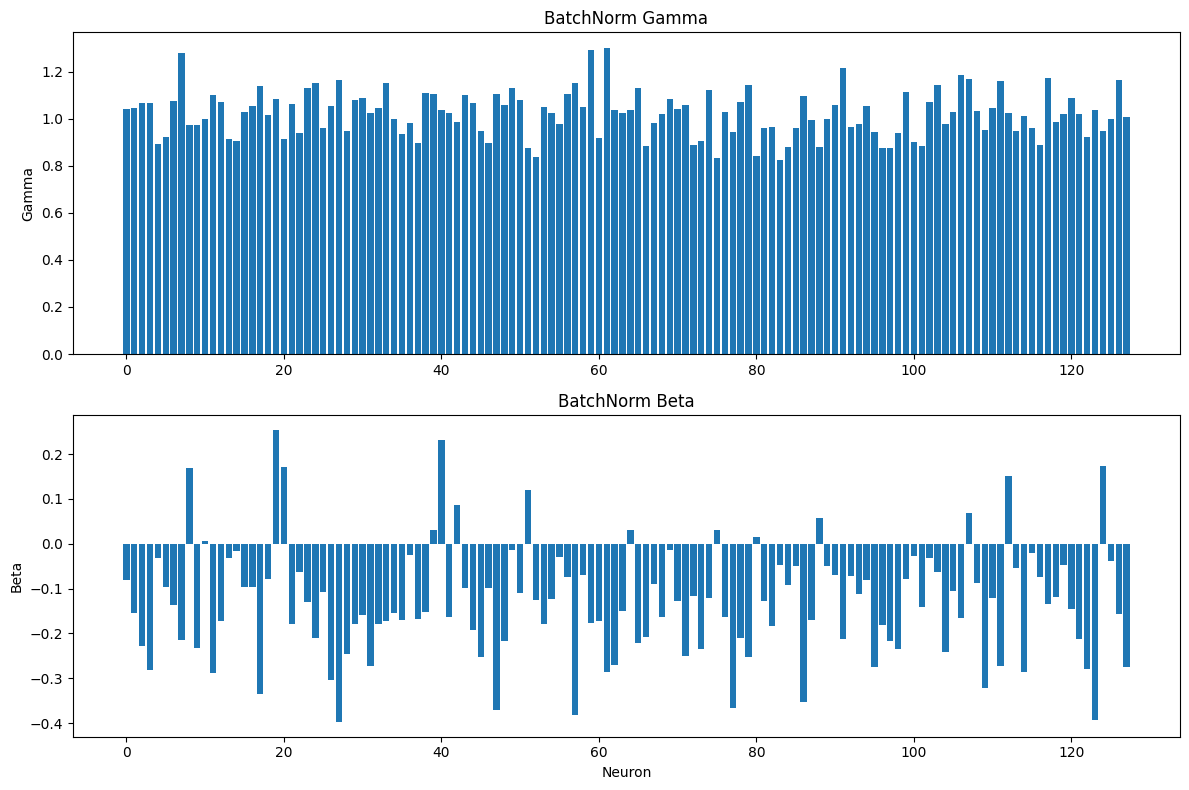

In [69]:
# Plot gamma and beta
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].bar(np.arange(len(gamma)), gamma)
axes[0].set_title("BatchNorm Gamma")
axes[0].set_ylabel("Gamma")
axes[1].bar(np.arange(len(beta)), beta)
axes[1].set_title("BatchNorm Beta")
axes[1].set_xlabel("Neuron")
axes[1].set_ylabel("Beta")
plt.tight_layout()
plt.savefig("plots/batchnorm_gamma_beta.png", dpi=150)
plt.show()

### Observation

The gamma and beta charts show learned scale and shift values for the first BatchNorm layer. Small absolute gamma values suggest a channel is scaled down, but do not alone prove it is useless to the network.


# Task 7 - Optimizers, Learning Rate & Final Comparison

### Objective
Now I will compare five optimizers using the stronger configuration:

`ReLU + He Normal + BatchNorm + BCE`

### Optimizer reference

| Optimizer | Main idea | What to compare |
|---|---|---|
| SGD | One learning rate for all parameters | Speed and stability |
| SGD + Momentum | Adds a running direction from past gradients | Smoother updates |
| RMSprop | Scales updates using recent squared gradients | Adaptation to different gradient sizes |
| Adam | Combines first and second moment estimates | Convergence and validation F1 |
| Adam (explicit) | `beta_1 = 0.9`, `beta_2 = 0.999`, learning rate `0.001` | Check against Keras defaults |

In Adam, `beta_1` controls the moving average of gradients and `beta_2` controls the moving average of squared gradients.

In [70]:
# SGD optimizer model

model_sgd = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="SGD",
    loss="binary_crossentropy"
)

history_sgd = model_sgd.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8046 - loss: 0.4049 - val_accuracy: 0.8353 - val_loss: 0.3497
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8362 - loss: 0.3479 - val_accuracy: 0.8472 - val_loss: 0.3334
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8418 - loss: 0.3381 - val_accuracy: 0.8494 - val_loss: 0.3270
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8437 - loss: 0.3327 - val_accuracy: 0.8494 - val_loss: 0.3235
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8460 - loss: 0.3291 - val_accuracy: 0.8491 - val_loss: 0.3214
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8466 - loss: 0.3264 - val_accuracy: 0.8502 - val_loss: 0.3200
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8477 - loss: 0.3243 - val_accuracy: 0.8507 - val_loss: 0.3190
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8490 - loss: 0.3225 - val_accuracy: 0.

### Observation

SGD uses a fixed learning rate for all parameters. Compare its validation-accuracy curve and validation F1 with adaptive optimizers.


In [71]:
# SGD + Momentum optimizer model

model_sgd_momentum = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="SGD + Momentum",
    loss="binary_crossentropy"
)

history_sgd_momentum = model_sgd_momentum.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8326 - loss: 0.3518 - val_accuracy: 0.8499 - val_loss: 0.3207
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8494 - loss: 0.3219 - val_accuracy: 0.8530 - val_loss: 0.3176
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8519 - loss: 0.3166 - val_accuracy: 0.8532 - val_loss: 0.3170
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8538 - loss: 0.3130 - val_accuracy: 0.8507 - val_loss: 0.3163
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8549 - loss: 0.3100 - val_accuracy: 0.8496 - val_loss: 0.3159
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8561 - loss: 0.3075 - val_accuracy: 0.8499 - val_loss: 0.3164
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8580 - loss: 0.3051 - val_accuracy: 0.8507 - val_loss: 0.3168
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8593 - loss: 0.3029 - val_accuracy: 0.

### Observation

Momentum combines current gradients with a running direction from prior updates. Check whether the curve rises faster or fluctuates less than vanilla SGD in this run.


In [72]:
# RMSprop optimizer model

model_rmsprop = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="RMSprop",
    loss="binary_crossentropy"
)

history_rmsprop = model_rmsprop.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8343 - loss: 0.3565 - val_accuracy: 0.8502 - val_loss: 0.3189
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8513 - loss: 0.3201 - val_accuracy: 0.8541 - val_loss: 0.3165
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8543 - loss: 0.3136 - val_accuracy: 0.8535 - val_loss: 0.3170
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8575 - loss: 0.3087 - val_accuracy: 0.8535 - val_loss: 0.3177
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8595 - loss: 0.3046 - val_accuracy: 0.8513 - val_loss: 0.3185
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8610 - loss: 0.3011 - val_accuracy: 0.8496 - val_loss: 0.3197
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8627 - loss: 0.2979 - val_accuracy: 0.8491 - val_loss: 0.3209
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8646 - loss: 0.2946 - val_accuracy: 0.

### Observation

RMSprop adapts parameter update sizes using recent squared gradients. Compare its convergence and final validation F1 with SGD and Adam.


In [73]:
# Adam optimizer model

model_adam = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="Adam",
    loss="binary_crossentropy"
)

history_adam = model_adam.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8390 - loss: 0.3443 - val_accuracy: 0.8530 - val_loss: 0.3196
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8517 - loss: 0.3181 - val_accuracy: 0.8546 - val_loss: 0.3167
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8549 - loss: 0.3110 - val_accuracy: 0.8546 - val_loss: 0.3165
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8572 - loss: 0.3057 - val_accuracy: 0.8541 - val_loss: 0.3167
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8599 - loss: 0.3012 - val_accuracy: 0.8549 - val_loss: 0.3174
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8622 - loss: 0.2972 - val_accuracy: 0.8519 - val_loss: 0.3190
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8643 - loss: 0.2931 - val_accuracy: 0.8483 - val_loss: 0.3206
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8662 - loss: 0.2891 - val_accuracy: 0.

### Observation

Adam uses first- and second-moment estimates; the run's validation curve indicates how effectively it trains this model on these features.


In [74]:
# Adam Explicit optimizer model

model_adam_explicit = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer="Adam Explicit",
    loss="binary_crossentropy"
)

history_adam_explicit = model_adam_explicit.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8307 - loss: 0.3594 - val_accuracy: 0.8507 - val_loss: 0.3189
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8509 - loss: 0.3185 - val_accuracy: 0.8505 - val_loss: 0.3168
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8542 - loss: 0.3115 - val_accuracy: 0.8527 - val_loss: 0.3173
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8575 - loss: 0.3064 - val_accuracy: 0.8519 - val_loss: 0.3177
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8598 - loss: 0.3022 - val_accuracy: 0.8496 - val_loss: 0.3181
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8622 - loss: 0.2982 - val_accuracy: 0.8491 - val_loss: 0.3192
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8646 - loss: 0.2942 - val_accuracy: 0.8507 - val_loss: 0.3196
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8672 - loss: 0.2903 - val_accuracy: 0.

### Observation

Default Adam and explicitly configured Adam should behave similarly under the same seed and identical data, though nondeterministic kernels or execution differences can create small discrepancies.


SGD: first reached 83% at epoch 1
SGD + Momentum: first reached 83% at epoch 1
RMSprop: first reached 83% at epoch 1
Adam: first reached 83% at epoch 1
Adam Explicit: first reached 83% at epoch 1


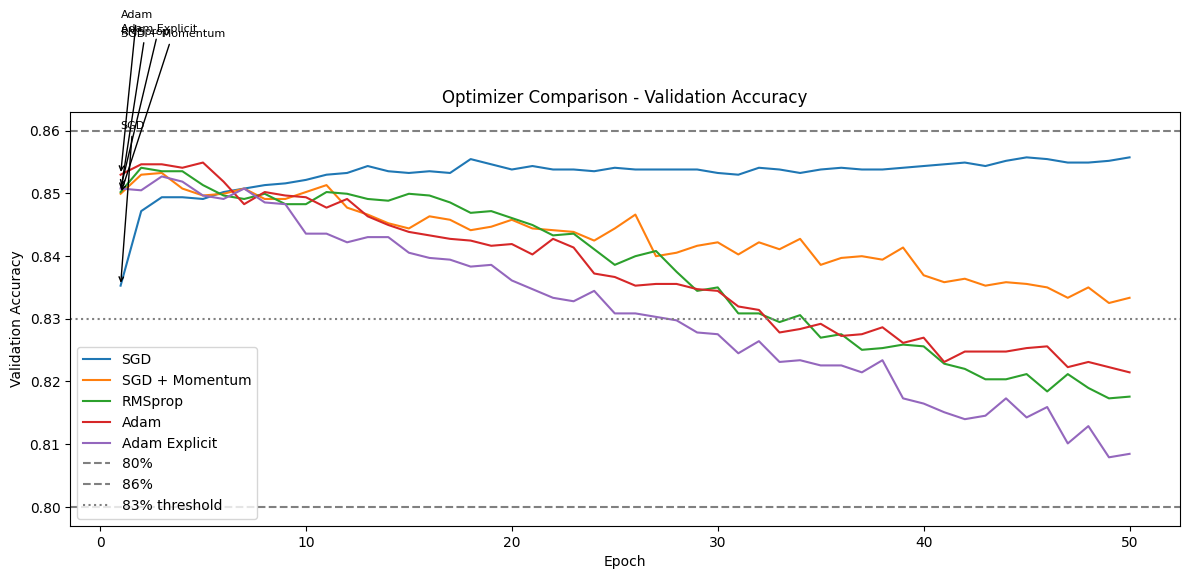

In [75]:
# Compare validation accuracy and mark the first epoch above 83%
optimizer_histories = [
    ("SGD", history_sgd),
    ("SGD + Momentum", history_sgd_momentum),
    ("RMSprop", history_rmsprop),
    ("Adam", history_adam),
    ("Adam Explicit", history_adam_explicit)
]

plt.figure(figsize=(12, 6))
for name, history in optimizer_histories:
    values = np.asarray(history.history["val_accuracy"])
    epochs = np.arange(1, len(values) + 1)
    plt.plot(epochs, values, label=name)
    crossed = np.flatnonzero(values >= 0.83)
    if len(crossed):
        epoch = int(crossed[0] + 1)
        plt.annotate(name, (epoch, values[epoch - 1]),
                     xytext=(epoch, min(0.98, values[epoch - 1] + 0.025)),
                     arrowprops={"arrowstyle": "->"}, fontsize=8)
        print(f"{name}: first reached 83% at epoch {epoch}")
    else:
        print(f"{name}: did not reach 83% in this run")

for level, style, label in [(0.80, "--", "80%"), (0.86, "--", "86%"), (0.83, ":", "83% threshold")]:
    plt.axhline(level, linestyle=style, color="gray", label=label)
plt.title("Optimizer Comparison - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("plots/optimiser_convergence.png", dpi=150)
plt.show()

### Observation

The dashed lines mark 80% and 86%, while the arrows label first crossings of 83%. Printed messages clarify when a model never reaches that threshold.


In [76]:
# Evaluate optimizer models on validation data for selection

optimizer_models = {
    "SGD": model_sgd,
    "SGD + Momentum": model_sgd_momentum,
    "RMSprop": model_rmsprop,
    "Adam": model_adam,
    "Adam Explicit": model_adam_explicit
}

optimizer_f1 = {}
for name, model in optimizer_models.items():
    prob = model.predict(X_val, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    optimizer_f1[name] = f1_score(y_val, pred, zero_division=0)

print("Validation F1 by optimizer:")
print(pd.Series(optimizer_f1).sort_values(ascending=False).round(4))

Validation F1 by optimizer:
SGD               0.6844
SGD + Momentum    0.6560
RMSprop           0.6216
Adam              0.6213
Adam Explicit     0.5682
dtype: float64


### Observation

The optimizer ranking is based on validation F1. The highest value determines the selected optimizer; test-set values are reserved for the final comparison table.


In [77]:
# Select the best optimizer

best_optimizer = max(
    optimizer_f1,
    key=optimizer_f1.get
)

print("Best optimizer:", best_optimizer)

Best optimizer: SGD


### Observation

The selected optimizer is the maximum validation-F1 row. Compare its learning dynamics with the convergence plot, not with a single test score used during tuning.


In [78]:
# SGD learning-rate experiment (learning rate = 0.0001)

sgd_0001 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.SGD(learning_rate=0.0001),
    loss="binary_crossentropy"
)

history_sgd_0001 = sgd_0001.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.2647 - loss: 1.1145 - val_accuracy: 0.2645 - val_loss: 1.0261
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2863 - loss: 0.9866 - val_accuracy: 0.3032 - val_loss: 0.9197
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3287 - loss: 0.8834 - val_accuracy: 0.3632 - val_loss: 0.8296
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3961 - loss: 0.8013 - val_accuracy: 0.4400 - val_loss: 0.7583
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4878 - loss: 0.7365 - val_accuracy: 0.5517 - val_loss: 0.7023
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.5748 - loss: 0.6855 - val_accuracy: 0.6180 - val_loss: 0.6581
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6354 - loss: 0.6452 - val_accuracy: 0.6697 - val_loss: 0.6231
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6790 - loss: 0.6131 - val_accuracy: 0.

### Observation

At learning rate 0.0001, inspect whether SGD's validation loss decreases slowly. The actual slope in this run determines the conclusion.


In [79]:
# SGD learning-rate experiment (learning rate = 0.001)

sgd_001 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.SGD(learning_rate=0.001),
    loss="binary_crossentropy"
)

history_sgd_001 = sgd_001.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6865 - loss: 0.6417 - val_accuracy: 0.7438 - val_loss: 0.5376
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7775 - loss: 0.4843 - val_accuracy: 0.7966 - val_loss: 0.4468
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8073 - loss: 0.4277 - val_accuracy: 0.8145 - val_loss: 0.4108
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8201 - loss: 0.4022 - val_accuracy: 0.8209 - val_loss: 0.3925
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8250 - loss: 0.3878 - val_accuracy: 0.8245 - val_loss: 0.3810
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8275 - loss: 0.3785 - val_accuracy: 0.8256 - val_loss: 0.3730
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8296 - loss: 0.3718 - val_accuracy: 0.8273 - val_loss: 0.3670
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8315 - loss: 0.3667 - val_accuracy: 0.

### Observation

This is the 0.001 SGD run. Compare it with the 0.0001, 0.01 and 0.1 curves; only the learning rate is changed.


In [80]:
# SGD learning-rate experiment (learning rate = 0.01)

sgd_01 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss="binary_crossentropy"
)

history_sgd_01 = sgd_01.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8152 - loss: 0.4048 - val_accuracy: 0.8361 - val_loss: 0.3525
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8383 - loss: 0.3511 - val_accuracy: 0.8413 - val_loss: 0.3359
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8429 - loss: 0.3401 - val_accuracy: 0.8460 - val_loss: 0.3290
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8450 - loss: 0.3341 - val_accuracy: 0.8477 - val_loss: 0.3253
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8462 - loss: 0.3303 - val_accuracy: 0.8502 - val_loss: 0.3230
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8477 - loss: 0.3275 - val_accuracy: 0.8502 - val_loss: 0.3216
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8480 - loss: 0.3252 - val_accuracy: 0.8510 - val_loss: 0.3206
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8489 - loss: 0.3234 - val_accuracy: 0.

### Observation

This is the 0.01 SGD run. Look for a faster loss reduction versus instability or oscillation, and confirm with the plotted values.


In [81]:
# SGD learning-rate experiment (learning rate = 0.1)

sgd_1 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss="binary_crossentropy"
)

history_sgd_1 = sgd_1.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8376 - loss: 0.3462 - val_accuracy: 0.8480 - val_loss: 0.3227
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8488 - loss: 0.3241 - val_accuracy: 0.8502 - val_loss: 0.3195
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8524 - loss: 0.3183 - val_accuracy: 0.8499 - val_loss: 0.3183
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8542 - loss: 0.3142 - val_accuracy: 0.8527 - val_loss: 0.3188
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8559 - loss: 0.3108 - val_accuracy: 0.8516 - val_loss: 0.3194
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8575 - loss: 0.3079 - val_accuracy: 0.8510 - val_loss: 0.3201
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8588 - loss: 0.3051 - val_accuracy: 0.8507 - val_loss: 0.3213
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8604 - loss: 0.3027 - val_accuracy: 0.

### Observation

This is the 0.1 SGD run. If the validation loss oscillates or grows, that is evidence the rate may be too large for this setup; record the observed curve.


In [82]:
# Adam learning-rate experiment (learning rate = 0.0001)

adam_0001 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy"
)

history_adam_0001 = adam_0001.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7940 - loss: 0.4529 - val_accuracy: 0.8411 - val_loss: 0.3689
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8393 - loss: 0.3519 - val_accuracy: 0.8447 - val_loss: 0.3349
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8441 - loss: 0.3346 - val_accuracy: 0.8491 - val_loss: 0.3259
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8466 - loss: 0.3274 - val_accuracy: 0.8507 - val_loss: 0.3220
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8484 - loss: 0.3231 - val_accuracy: 0.8480 - val_loss: 0.3197
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8499 - loss: 0.3201 - val_accuracy: 0.8485 - val_loss: 0.3184
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8509 - loss: 0.3177 - val_accuracy: 0.8505 - val_loss: 0.3176
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8523 - loss: 0.3157 - val_accuracy: 0.

### Observation

This is Adam at 0.0001. A smoother but slower curve than 0.001 would be consistent with a smaller step size, but the plotted result is authoritative.


In [83]:
# Adam learning-rate experiment (learning rate = 0.001)

adam_001 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy"
)

history_adam_001 = adam_001.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8375 - loss: 0.3462 - val_accuracy: 0.8488 - val_loss: 0.3192
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8509 - loss: 0.3178 - val_accuracy: 0.8513 - val_loss: 0.3164
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8547 - loss: 0.3106 - val_accuracy: 0.8510 - val_loss: 0.3163
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8571 - loss: 0.3055 - val_accuracy: 0.8510 - val_loss: 0.3168
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8601 - loss: 0.3008 - val_accuracy: 0.8480 - val_loss: 0.3179
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8626 - loss: 0.2966 - val_accuracy: 0.8477 - val_loss: 0.3187
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8649 - loss: 0.2925 - val_accuracy: 0.8469 - val_loss: 0.3199
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8673 - loss: 0.2885 - val_accuracy: 0.

### Observation

This is the default-scale Adam rate of 0.001. Compare its validation-loss trajectory with the lower and higher learning rates.


In [84]:
# Adam learning-rate experiment (learning rate = 0.01)

adam_01 = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation="relu",
    initializer="he_normal",
    use_batch_norm=True,
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy"
)

history_adam_01 = adam_01.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8411 - loss: 0.3391 - val_accuracy: 0.8494 - val_loss: 0.3267
Epoch 2/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8495 - loss: 0.3218 - val_accuracy: 0.8472 - val_loss: 0.3241
Epoch 3/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8526 - loss: 0.3157 - val_accuracy: 0.8496 - val_loss: 0.3228
Epoch 4/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8549 - loss: 0.3110 - val_accuracy: 0.8488 - val_loss: 0.3219
Epoch 5/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8562 - loss: 0.3069 - val_accuracy: 0.8502 - val_loss: 0.3209
Epoch 6/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8583 - loss: 0.3025 - val_accuracy: 0.8460 - val_loss: 0.3232
Epoch 7/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8605 - loss: 0.2983 - val_accuracy: 0.8488 - val_loss: 0.3233
Epoch 8/30
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8623 - loss: 0.2946 - val_accuracy: 0.

### Observation

This is Adam at 0.01. Check whether its loss curve converges faster or becomes less stable than the default-rate curve.


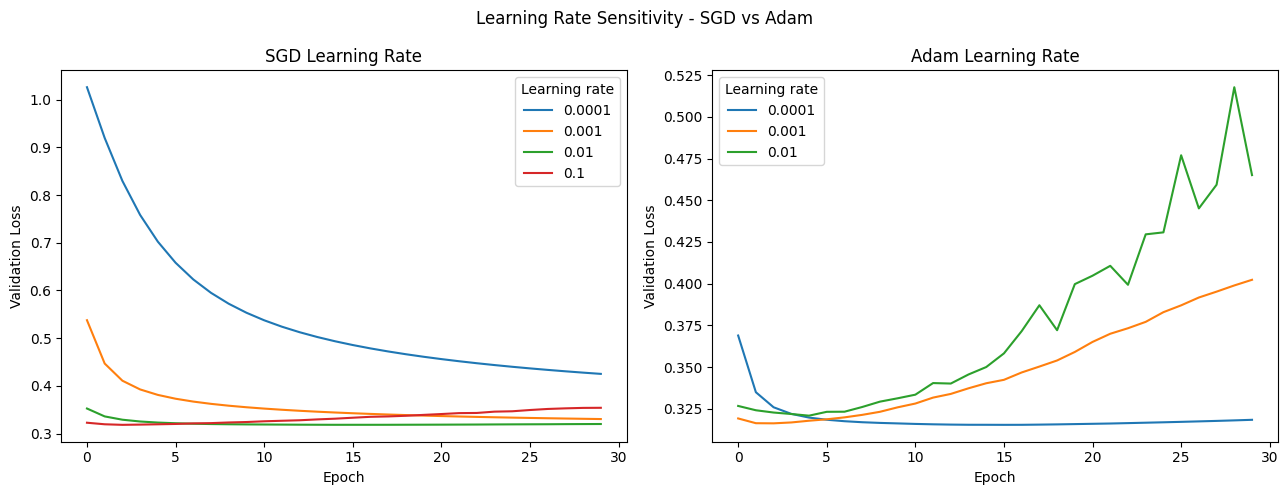

In [85]:
# Compare validation loss for the four SGD rates and three Adam rates
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sgd_runs = [
    ("0.0001", history_sgd_0001),
    ("0.001", history_sgd_001),
    ("0.01", history_sgd_01),
    ("0.1", history_sgd_1)
]
adam_runs = [
    ("0.0001", history_adam_0001),
    ("0.001", history_adam_001),
    ("0.01", history_adam_01)
]

for ax, runs, title in [
    (axes[0], sgd_runs, "SGD Learning Rate"),
    (axes[1], adam_runs, "Adam Learning Rate")
]:
    for rate, history in runs:
        ax.plot(history.history["val_loss"], label=rate)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation Loss")
    ax.legend(title="Learning rate")

plt.suptitle("Learning Rate Sensitivity - SGD vs Adam")
plt.tight_layout()
plt.savefig("plots/learning_rate_sensitivity.png", dpi=150)
plt.show()

### Observation

The two panels make SGD and Adam learning-rate sensitivity comparable. Prefer the rate with stable lower validation loss, not simply the fastest initial drop.


# Final Combined ANN

### Objective
Now I will build one final model using the strongest activation, initializer and optimizer found in my experiments.

For loss, I will use Weighted BCE if it gave a better class-1 F1 than the baseline.

In [86]:
# Collect the best settings selected only on validation data

best_activation = activation_results.loc[
    activation_results["F1"].idxmax(), "Activation"
]
best_initializer = initializer_results.loc[
    initializer_results["Validation F1"].idxmax(), "Initializer"
]
best_optimizer = max(optimizer_f1, key=optimizer_f1.get)
use_weighted_bce = wbce_val_f1 > base_val_f1

print("Best activation by validation F1:", best_activation)
print("Best initializer by validation F1:", best_initializer)
print("Best optimizer by validation F1:", best_optimizer)
print("Use class-weighted BCE:", use_weighted_bce)
print("Selection rule: validation F1 only; test set remains reserved for final evaluation.")

Best activation by validation F1: Sigmoid
Best initializer by validation F1: He Uniform
Best optimizer by validation F1: SGD
Use class-weighted BCE: True
Selection rule: validation F1 only; test set remains reserved for final evaluation.


### Observation

Printed settings are selected from validation-F1 experiments. Weighted BCE is used only when its validation F1 exceeds the baseline validation F1.


In [87]:
# Final model - selected configuration, canonical BatchNorm order

best_activation_name = best_activation.lower()
final_initializer_name = best_initializer.lower().replace(" ", "_")

final_model = build_ann(
    input_dim=X_train.shape[1],
    hidden_units=(128, 64),
    activation=best_activation_name,
    initializer=final_initializer_name,
    use_batch_norm=True,
    optimizer=best_optimizer,
    loss="binary_crossentropy"
)
final_model.summary()

Model: "sequential_28"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_84 (Dense)                │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_26 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_27 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,457 (76.00 KB)

 Trainable params: 19,073 (74.50 KB)

 Non-trainable params: 384 (1.50 KB)

### Observation

The final summary should show two hidden layers and BatchNorm before each hidden activation, plus one sigmoid output. This fixes the earlier layer-order inconsistency.


In [88]:
# Train final model

if use_weighted_bce:

    history_final = final_model.fit(
        X_train,
        y_train,
        epochs=80,
        batch_size=64,
        validation_data=(X_val, y_val),
        class_weight=class_weight_dict,
        verbose=1
    )

else:

    history_final = final_model.fit(
        X_train,
        y_train,
        epochs=80,
        batch_size=64,
        validation_data=(X_val, y_val),
        verbose=1
    )

Epoch 1/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7247 - loss: 0.5278 - val_accuracy: 0.7756 - val_loss: 0.4644
Epoch 2/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7871 - loss: 0.4300 - val_accuracy: 0.7866 - val_loss: 0.4250
Epoch 3/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7902 - loss: 0.4134 - val_accuracy: 0.7919 - val_loss: 0.4118
Epoch 4/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7931 - loss: 0.4068 - val_accuracy: 0.7946 - val_loss: 0.4047
Epoch 5/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7950 - loss: 0.4030 - val_accuracy: 0.7974 - val_loss: 0.4002
Epoch 6/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7952 - loss: 0.4004 - val_accuracy: 0.8007 - val_loss: 0.3969
Epoch 7/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7966 - loss: 0.3986 - val_accuracy: 0.8024 - val_loss: 0.3944
Epoch 8/80
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7972 - loss: 0.3972 - val_accuracy: 0.

### Observation

The training log should contain 80 epochs. Class weights are passed only if Weighted BCE improved validation F1 over the baseline in this run.


In [89]:
# Final model evaluation

y_prob_final = final_model.predict(
    X_test,
    verbose=0
).ravel()

y_pred_final = (y_prob_final > 0.5).astype(int)

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final, zero_division=0)
final_recall = recall_score(y_test, y_pred_final, zero_division=0)
final_f1 = f1_score(y_test, y_pred_final, zero_division=0)
final_auc = roc_auc_score(y_test, y_prob_final)

print("Final Accuracy :", final_accuracy)
print("Final Precision:", final_precision)
print("Final Recall   :", final_recall)
print("Final F1       :", final_f1)
print("Final ROC-AUC  :", final_auc)

print("\nFinal classification report:")
print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["<=50K", ">50K"],
        zero_division=0
    )
)

Final Accuracy : 0.81934770591487
Final Precision: 0.5968769917144678
Final Recall   : 0.8354148082069581
Final F1       : 0.696282527881041
Final ROC-AUC  : 0.9094334201878453

Final classification report:
              precision    recall  f1-score   support

       <=50K       0.94      0.81      0.87      6803
        >50K       0.60      0.84      0.70      2242

    accuracy                           0.82      9045
   macro avg       0.77      0.82      0.78      9045
weighted avg       0.85      0.82      0.83      9045



### Observation

Report final test Accuracy, Precision, Recall, F1 and ROC-AUC from this cell. These results are a final evaluation, not the data used to choose the model.


# Full Results Comparison

### Calculate Test Metrics

In [90]:
def get_test_metrics(y_true, y_prob):
    y_pred = (y_prob > 0.5).astype(int)

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision(1)": precision_score(y_true, y_pred, zero_division=0),
        "Recall(1)": recall_score(y_true, y_pred, zero_division=0),
        "F1(1)": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }


### Best Activation Model

In [91]:
best_act_model = {
    "ReLU": model_relu,
    "Tanh": model_tanh,
    "Sigmoid": model_sigmoid,
    "ELU": model_elu
}[best_activation]


In [92]:
best_act_prob = best_act_model.predict(X_test, verbose=0).ravel()
best_act_metrics = get_test_metrics(y_test, best_act_prob)
best_act_metrics


{'Accuracy': 0.8505251520176893,
 'Precision(1)': 0.7716727716727717,
 'Recall(1)': 0.5637823371989296,
 'F1(1)': 0.6515463917525773,
 'ROC-AUC': np.float64(0.9110846437454851)}

### Observation

The selected activation model’s test metrics are recorded for the final comparison table.

### Best Weight Initializer Model

In [93]:
best_init_model = {
    "Glorot Uniform": model_glorot_uniform,
    "Glorot Normal": model_glorot_normal,
    "He Uniform": model_he_uniform,
    "He Normal": model_he_normal,
    "Zeros": model_zeros
}[best_initializer]


In [94]:
best_init_prob = best_init_model.predict(X_test, verbose=0).ravel()
best_init_metrics = get_test_metrics(y_test, best_init_prob)
best_init_metrics


{'Accuracy': 0.8377003869541183,
 'Precision(1)': 0.6988694758478932,
 'Recall(1)': 0.6066012488849242,
 'F1(1)': 0.6494746895893028,
 'ROC-AUC': np.float64(0.887238149774664)}

### Observation

The selected initializer model’s test metrics are recorded for the final comparison table.

### Best Optimizer Model

In [95]:
optimizer_model = optimizer_models[best_optimizer]


In [96]:
best_opt_prob = optimizer_model.predict(X_test, verbose=0).ravel()
best_opt_metrics = get_test_metrics(y_test, best_opt_prob)
best_opt_metrics


{'Accuracy': 0.8526257600884467,
 'Precision(1)': 0.7408585055643879,
 'Recall(1)': 0.623550401427297,
 'F1(1)': 0.6771615403245338,
 'ROC-AUC': np.float64(0.9075789161600663)}

### Observation

The optimizer shown here was selected using validation F1; its test metrics are reported here.

### Prepare Metrics for the Result Table

In [97]:
baseline_metrics = get_test_metrics(y_test, y_prob_base)
mse_metrics = get_test_metrics(y_test, y_prob_mse)
wbce_metrics = get_test_metrics(y_test, y_prob_wbce)


In [98]:
focal_metrics = get_test_metrics(y_test, y_prob_focal)
bn_metrics = get_test_metrics(y_test, y_prob_bn)
final_metrics = get_test_metrics(y_test, y_prob_final)


### Build the Result Table

In [99]:
results_rows = []


def add_result_row(model_name, activation, initializer, loss, batch_norm, optimizer, metrics):
    row = {
        "Model": model_name,
        "Activation": activation,
        "Init": initializer,
        "Loss": loss,
        "BatchNorm": batch_norm,
        "Optimizer": optimizer,
    }
    row.update(metrics)
    results_rows.append(row)


In [100]:
add_result_row(
    "Baseline", "ReLU", "Glorot Uniform", "BCE", "No", "Adam",
    baseline_metrics
)

add_result_row(
    "Best Activation", best_activation, "Glorot Uniform", "BCE", "No", "Adam",
    best_act_metrics
)


In [101]:
add_result_row(
    "Best Initializer", "ReLU", best_initializer, "BCE", "No", "Adam",
    best_init_metrics
)

add_result_row(
    "MSE", "ReLU", "He Normal", "MSE", "No", "Adam",
    mse_metrics
)


In [102]:
add_result_row(
    "Weighted BCE", "ReLU", "He Normal", "Weighted BCE", "No", "Adam",
    wbce_metrics
)

add_result_row(
    "Focal Loss", "ReLU", "He Normal", "Focal Loss", "No", "Adam",
    focal_metrics
)


In [103]:
add_result_row(
    "BatchNorm", "ReLU", "He Normal", "BCE", "Yes", "Adam",
    bn_metrics
)

add_result_row(
    "Best Optimizer", "ReLU", "He Normal", "BCE", "Yes", best_optimizer,
    best_opt_metrics
)


In [104]:
add_result_row(
    "Final Combined",
    best_activation,
    best_initializer,
    "Weighted BCE" if use_weighted_bce else "BCE",
    "Yes",
    best_optimizer,
    final_metrics
)


In [105]:
results = pd.DataFrame(results_rows)

results = results[[
    "Model", "Activation", "Init", "Loss", "BatchNorm", "Optimizer",
    "Accuracy", "Precision(1)", "Recall(1)", "F1(1)", "ROC-AUC"
]]

results


,Model,Activation,Init,Loss,BatchNorm,Optimizer,Accuracy,Precision(1),Recall(1),F1(1),ROC-AUC
0,Baseline,ReLU,Glorot Uniform,BCE,No,Adam,0.837479,0.731138,0.544603,0.624233,0.882504
1,Best Activation,Sigmoid,Glorot Uniform,BCE,No,Adam,0.850525,0.771673,0.563782,0.651546,0.911085
2,Best Initializer,ReLU,He Uniform,BCE,No,Adam,0.837700,0.698869,0.606601,0.649475,0.887238
3,MSE,ReLU,He Normal,MSE,No,Adam,0.837037,0.733577,0.537913,0.620690,0.893097
4,Weighted BCE,ReLU,He Normal,Weighted BCE,No,Adam,0.818684,0.609534,0.747101,0.671343,0.883572
5,Focal Loss,ReLU,He Normal,Focal Loss,No,Adam,0.823217,0.803016,0.380018,0.515895,0.882232
6,BatchNorm,ReLU,He Normal,BCE,Yes,Adam,0.823770,0.709845,0.488849,0.578975,0.870675
7,Best Optimizer,ReLU,He Normal,BCE,Yes,SGD,0.852626,0.740859,0.623550,0.677162,0.907579
8,Final Combined,Sigmoid,He Uniform,Weighted BCE,Yes,SGD,0.819348,0.596877,0.835415,0.696283,0.909433


### Display the Formatted Result Table

In [106]:
display(
    results.style
    .highlight_max(subset=["F1(1)", "ROC-AUC"], color="#ffcccc")
    .format({
        "Accuracy": "{:.4f}",
        "Precision(1)": "{:.4f}",
        "Recall(1)": "{:.4f}",
        "F1(1)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


,Model,Activation,Init,Loss,BatchNorm,Optimizer,Accuracy,Precision(1),Recall(1),F1(1),ROC-AUC
0,Baseline,ReLU,Glorot Uniform,BCE,No,Adam,0.8375,0.7311,0.5446,0.6242,0.8825
1,Best Activation,Sigmoid,Glorot Uniform,BCE,No,Adam,0.8505,0.7717,0.5638,0.6515,0.9111
2,Best Initializer,ReLU,He Uniform,BCE,No,Adam,0.8377,0.6989,0.6066,0.6495,0.8872
3,MSE,ReLU,He Normal,MSE,No,Adam,0.8370,0.7336,0.5379,0.6207,0.8931
4,Weighted BCE,ReLU,He Normal,Weighted BCE,No,Adam,0.8187,0.6095,0.7471,0.6713,0.8836
5,Focal Loss,ReLU,He Normal,Focal Loss,No,Adam,0.8232,0.8030,0.3800,0.5159,0.8822
6,BatchNorm,ReLU,He Normal,BCE,Yes,Adam,0.8238,0.7098,0.4888,0.5790,0.8707
7,Best Optimizer,ReLU,He Normal,BCE,Yes,SGD,0.8526,0.7409,0.6236,0.6772,0.9076
8,Final Combined,Sigmoid,He Uniform,Weighted BCE,Yes,SGD,0.8193,0.5969,0.8354,0.6963,0.9094


### Save the Result Table as CSV

In [107]:
results.to_csv("results_table.csv", index=False)
print("Saved results_table.csv")


Saved results_table.csv


### Save the Result Table as an Image

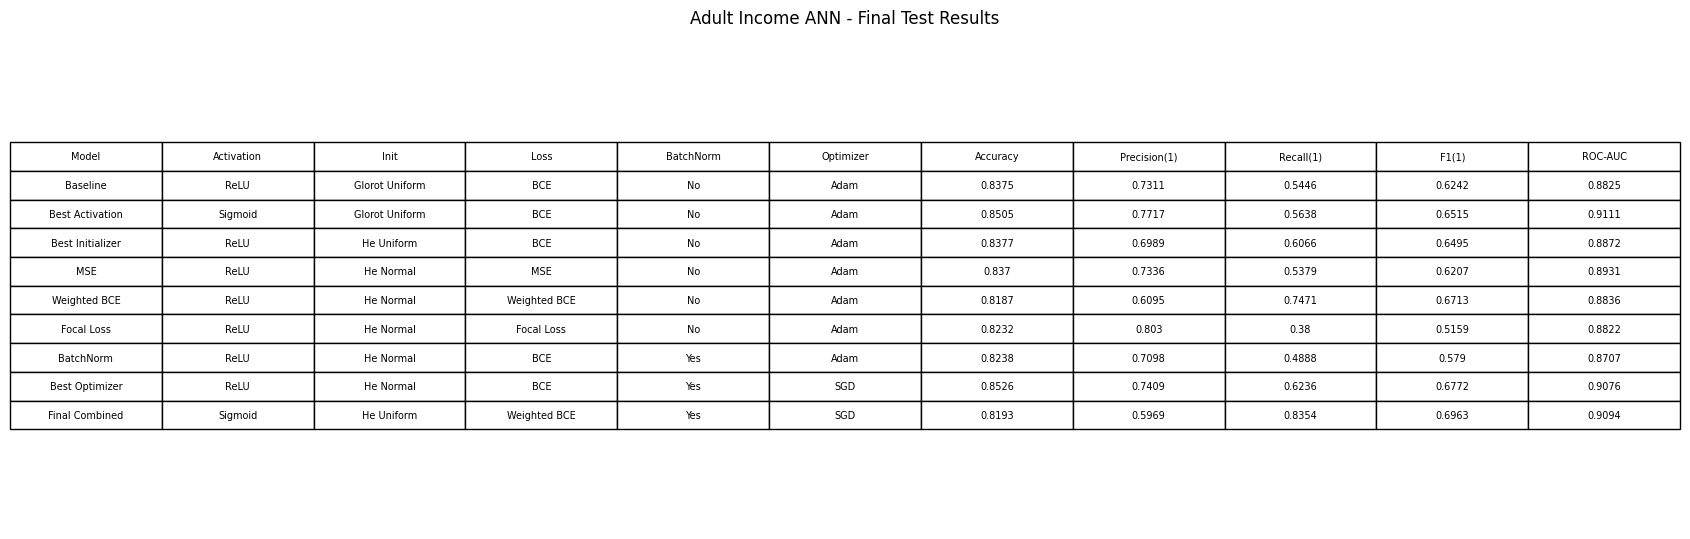

In [108]:
fig, ax = plt.subplots(figsize=(17, 5.5))
ax.axis("off")

results_for_plot = results.round(4)
result_table = ax.table(
    cellText=results_for_plot.values,
    colLabels=results_for_plot.columns,
    loc="center",
    cellLoc="center"
)
result_table.auto_set_font_size(False)
result_table.set_fontsize(7)
result_table.scale(1, 1.5)

plt.title("Adult Income ANN - Final Test Results", pad=14)
plt.tight_layout()
plt.savefig("plots/results_table.png", dpi=180, bbox_inches="tight")
plt.show()


### Observation

The table compares selected models on the held-out test set. The highlighted maximum F1 and ROC-AUC are descriptive; they should not be used to retune the model after seeing test results.


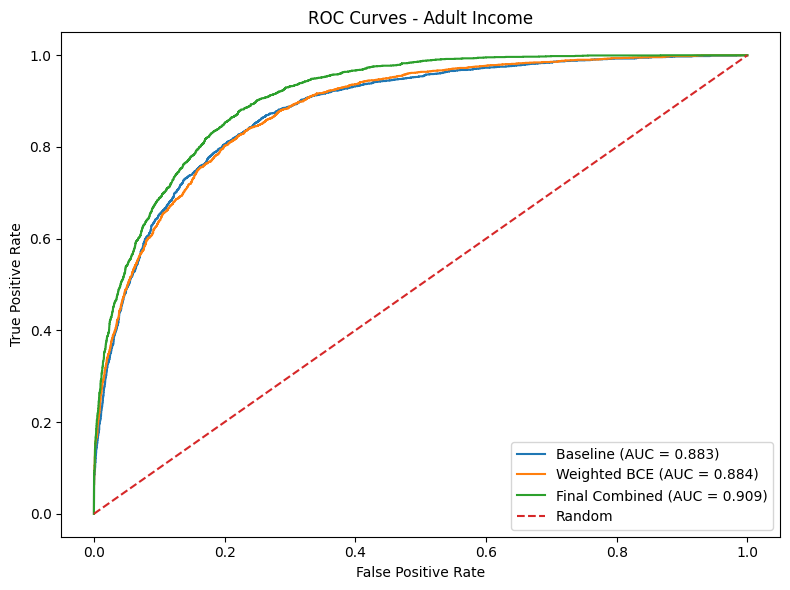

In [109]:
# ROC curves for the baseline, weighted BCE and final model
roc_models = [
    ("Baseline", y_prob_base),
    ("Weighted BCE", y_prob_wbce),
    ("Final Combined", y_prob_final)
]

plt.figure(figsize=(8, 6))
for name, prob in roc_models:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
plt.title("ROC Curves - Adult Income")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.savefig("plots/roc_curves.png", dpi=150)
plt.show()

### Observation

The ROC curves compare the baseline, Weighted BCE and final model at different thresholds. The AUC in the legend lets you compare ranking quality independently of the 0.5 classification threshold.


In [110]:
# Compare individual technique impact using validation F1

best_act_val_f1 = float(activation_results["F1"].max())
best_init_val_f1 = float(initializer_results["Validation F1"].max())
best_opt_val_f1 = float(optimizer_f1[best_optimizer])

impact = pd.DataFrame({
    "Technique": ["Activation", "Initializer", "Weighted BCE", "Focal Loss", "BatchNorm", "Optimizer"],
    "Validation F1": [
        best_act_val_f1,
        best_init_val_f1,
        wbce_val_f1,
        focal_val_f1,
        bn_val_f1,
        best_opt_val_f1
    ]
})
impact["Improvement vs baseline"] = impact["Validation F1"] - base_val_f1

display(impact.sort_values("Improvement vs baseline", ascending=False).round(4))
print("The largest observed improvement is the first row after sorting, based on validation F1.")

,Technique,Validation F1,Improvement vs baseline
5,Optimizer,0.6844,0.0616
2,Weighted BCE,0.6696,0.0468
0,Activation,0.6615,0.0387
1,Initializer,0.6481,0.0254
4,BatchNorm,0.5861,-0.0367
3,Focal Loss,0.5353,-0.0874


The largest observed improvement is the first row after sorting, based on validation F1.


### Observation

The impact table sorts changes in validation F1 relative to the baseline. The top row is the largest observed change in this run, not a guarantee that the same technique wins on another split or seed.


# Final Conclusion

Use the results generated by this notebook to complete the points below. Keep the conclusions tied to the measured results rather than assuming one method always wins.

- **Baseline:** report the test Accuracy, class-1 Precision, Recall, F1 and ROC-AUC.
- **Activation and initializer:** name the highest validation-F1 choices and report their test metrics from the results table.
- **Loss:** compare BCE, Weighted BCE and Focal Loss on validation F1 and note any Precision/Recall trade-off.
- **BatchNorm and optimizers:** use the validation curves and learned gamma/beta values as evidence.
- **Final model:** report the metrics from the held-out test set.